# Supply-chain relationships of a company, from Bigdata.com and OpenAI

This notebook finds the **suppliers, customers, partners and competitors** of a company (and of the
companies around it) in what SEC filings, earnings calls, press releases and news say, following
RavenPack's current supply-chain knowledge-graph approach:

1. **Search** Bigdata.com for the passages ("chunks") that state business relationships of the
   company: 61 search sentences over SEC filings, transcripts and news, one search per month.
2. **Name** the companies Bigdata.com tags in each chunk (Knowledge Graph).
3. **Classify** each chunk with an OpenAI model: which relationships between the companies it names
   does the text state, with which evidence code, in which words.
4. **Resolve** the companies the model finds in the text that Bigdata.com did not tag.
5. **Build the graph**: one record per piece of evidence, grouped into relationships with a status
   (active or inactive), their number of records, documents and sources, and an explanation. A
   relationship seen only in news needs publishers trusted enough: their Bigdata.com rank.

**Example in this notebook:** NVIDIA (`E09E2B`), from 2025-11-16 to 2026-11-15.

**What you get**, in `output/`:

| File | One row per | Contents |
|---|---|---|
| `<LABEL>_counterparties.csv` | company related to the chosen company, and role | supplier, customer, partner or competitor; status; records, documents and sources; explanation and link |
| `<LABEL>_relationships.csv` | relationship of the graph | the two companies, type, status, dates, records, documents, sources, explanation with its quote and link |
| `<LABEL>_records.csv` | piece of evidence (the grounding) | the quoted sentence, evidence code, document, date, headline, URL and chunk id |
| `<LABEL>_rejections.csv` | relation the model or the checks rejected | the reason and the quoted text |
| `<LABEL>_held_out.csv` | relationship seen only in news that the news rule leaves out | the two companies, type, the confidence and ranks of its publishers, records, explanation and link |
| `<LABEL>_related_companies.png` | | the chart of the related companies |

**Time and cost, approximately (the NVIDIA example):** about 15 minutes of search and 2 h 45 min
of classification, about 8,300 OpenAI calls (~8 USD). Step 5 prints the estimate for your
parameters before it calls OpenAI. Everything is cached in `cache/`: a run that stops resumes where
it stopped, and running the notebook again costs nothing.

## 0. Setup

- A **Bigdata.com API key** and an **OpenAI API key** with access to the model in `MODEL` (section 1).
- Python 3.12 and [uv](https://docs.astral.sh/uv/). From this folder:
  ```bash
  uv sync --locked      # installs the exact versions of uv.lock
  uv run jupyter lab    # or open the notebook in VS Code with the .venv kernel
  ```
- The keys as the environment variables `BIGDATA_API_KEY` and `OPENAI_API_KEY`, or in a `.env` file
  in this folder (`BIGDATA_API_KEY=...` lines). If they are missing, the notebook asks for them.

In [1]:
import contextlib
import copy
import csv
import gzip
import hashlib
import io
import json
import logging
import math
import os
import queue
import re
import threading
import time
import tomllib
from collections import Counter, defaultdict, deque
from collections.abc import Iterable, Mapping, Sequence
from concurrent.futures import ThreadPoolExecutor, as_completed
from dataclasses import dataclass, field
from datetime import date, timedelta
from functools import cached_property
from getpass import getpass
from pathlib import Path

import matplotlib.pyplot as plt
import openai
import pandas as pd
import requests
from bigdata_smart_batching import execute_search, plan_search
from bigdata_smart_batching import search_function as lib_search
from IPython.display import display
from matplotlib.lines import Line2D

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_columns", 50)
# the smart batching library sets the root logger to print every INFO line: show warnings only
logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s", force=True)
for handler in logging.getLogger().handlers:
    handler.setLevel(logging.WARNING)
log = logging.getLogger("supply_chain")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

In [2]:
def read_key(name: str) -> str:
    """A key from the environment, else from .env in this folder, else asked for. Never printed."""
    if os.environ.get(name):
        return os.environ[name]
    env = Path(".env")
    if env.exists():
        for line in env.read_text().splitlines():
            k, _, v = line.partition("=")
            if k.strip().removeprefix("export ").strip() == name and v.strip():
                return v.strip().strip("\"'")
    return getpass(f"{name}: ")


BIGDATA_API_KEY = read_key("BIGDATA_API_KEY")
OPENAI_API_KEY = read_key("OPENAI_API_KEY")
print("API keys loaded")

API keys loaded


## 1. Parameters

Change the company and the dates here. The other values are the defaults of the current approach.
To find another company's Bigdata.com id, run `kg.companies("Apple")` in section 3.

In [3]:
COMPANY_ID = "E09E2B"  # Bigdata.com entity id of the company (NVIDIA Corp.)
LABEL = "NVDA"  # a short name for the chart and the output files
START, END = date(2025, 11, 16), date(2026, 11, 15)  # the last year, both days included

# Share of the chunks found that the model reads, by source type. The choice is fixed per chunk
# (a hash of its id), so raising a share later reads the same chunks plus new ones.
SHARE_1ST_CLASS = 1.0  # SEC filings, earnings calls and other transcripts
SHARE_PRESS_RELEASES = 1.0
SHARE_NEWS = 0.1  # news is about 90% of the chunks found for NVIDIA: 10% keeps the cost down
NEWS_LANGUAGES: list[str] = []  # e.g. ["en"]: only news first published in English; []: all

# Which relationships seen only in news enter the graph:
# "rank": each news publisher weighs by its Bigdata.com rank (RANK_1 and RANK_2: 1, RANK_3: 0.5,
#   RANK_4 and RANK_5: 0.2) and the relationship enters when the sum reaches NEWS_MIN_CONFIDENCE
#   (1: one rank 1-2 publisher, two rank 3 or five rank 4-5). A record from a filing, a call, a
#   transcript or a press release is enough on its own.
# "sources": a relationship seen only in press releases and news enters when NEWS_MIN_SOURCES
#   different publishers report it (1: every relationship enters).
NEWS_RULE = "rank"
NEWS_MIN_CONFIDENCE = 1.0  # the rank rule's threshold, more than 0 and at most 1
NEWS_MIN_SOURCES = 1  # the sources rule's threshold

INSTITUTIONS = True  # governments, agencies, universities... can be counterparties
CENTRAL_BANKS = False  # True: central banks too, in a commercial or project role only
SUPPLY_FIRST = True  # a supply the text calls a "partnership" is recorded as a supply

MODEL = "gpt-5.6-luna"
LLM_WORKERS = 8  # OpenAI calls in parallel
MAX_LLM_CALLS = None  # e.g. 100 for a quick, cheap test; None: every chunk

BIGDATA_URL = "https://api.bigdata.com"
SEARCH_REQUESTS_PER_MINUTE, SEARCH_WORKERS = 300, 8
CONFIG_DIR, CACHE_DIR, OUTPUT_DIR = Path("config"), Path("cache"), Path("output")
CACHE_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

## 2. The approach: the configuration files

The files in `config/` are those of the pipeline, unchanged:

| File | What it is |
|---|---|
| `search_sentences.csv` | 61 search sentences, each written like a text that states a relationship and searched in one Bigdata.com category (filings, transcripts or news) |
| `relationship_rules.toml` | the four relationship types (SUPPLIER_TO, CUSTOMER_OF, PARTNER_WITH, COMPETITOR_OF): definition, what counts, what does not, when it ends |
| `evidence_codes.csv` | 40 evidence codes, the kind of relationship the text states (components, contract manufacturing, joint development...) |
| `counterparty_categories.csv`, `excluded_institutions.csv` | which tagged entities can be a counterparty: companies and institutions, but not central banks, generic names or stock indices |
| `company_aliases.csv` | other names the model is told about (Hon Hai Precision: Foxconn) |
| `press_release_sources.csv` | press-release wires, to tell press releases from other news |

The prompt is built from these files (section 5).

In [4]:
EDGE_TYPES = ("SUPPLIER_TO", "CUSTOMER_OF", "PARTNER_WITH", "COMPETITOR_OF")
SYMMETRIC = frozenset({"PARTNER_WITH", "COMPETITOR_OF"})
COMPANY, INSTITUTION, CENTRAL_BANK = "company", "institution", "central_bank"


def read_csv(name: str) -> list[dict[str, str]]:
    with open(CONFIG_DIR / name, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


@dataclass(frozen=True)
class Sentence:
    sentence_id: str
    edge_type: str
    item: str
    query_text: str
    source: str  # the Bigdata.com category it searches: filings | transcripts | news


@dataclass(frozen=True)
class EvidenceCode:
    code: str
    edge_type: str
    category_code: str
    category: str
    label: str
    definition: str


@dataclass(frozen=True)
class Entity:
    entity_id: str
    name: str | None
    category: str | None  # Knowledge Graph category: "companies"...; "unknown" if it has none

    @property
    def is_company(self) -> bool:
        return self.category == "companies"


@dataclass(frozen=True)
class Counterparties:
    """Which tagged entities can be a counterparty: companies, and institutions not excluded."""

    categories: Mapping[str, str]  # Knowledge Graph category (lower case) -> company | institution
    excluded_patterns: tuple[tuple[str, str, str], ...]  # (group, pattern, contains|exact|suffix)
    institutions: bool
    central_banks: bool

    def kind(self, entity: Entity) -> str | None:
        """company, institution, or None (not a counterparty: the model does not see it)."""
        k = self.categories.get((entity.category or "").strip().lower())
        if k == COMPANY:
            return COMPANY
        if k == INSTITUTION and self.institutions:
            return None if self.excluded(entity.name) else INSTITUTION
        return None

    def excluded(self, name: str | None) -> str | None:
        """The group of an institution left out (central_bank, generic_name, market_index)."""
        n = " ".join(str(name or "").lower().replace("’", "'").split())
        for group, p, match in self.excluded_patterns:
            if group == CENTRAL_BANK and self.central_banks:
                continue
            if match == "exact":
                hit = n == p
            elif match == "suffix":
                hit = n == p or n.endswith(" " + p)
            else:
                hit = p in n
            if hit:
                return group
        return None


@dataclass(frozen=True)
class Taxonomy:
    sentences: tuple[Sentence, ...]
    codes: dict[str, EvidenceCode]
    rules: dict[str, dict]
    aliases: tuple[tuple[str, str], ...]  # (the listed name starts with, also called)
    counterparties: Counterparties
    supply_first: bool

    def is_valid(self, code: str | None, edge_type: str | None) -> bool:
        """The code exists and belongs to the relationship type."""
        c = self.codes.get(code) if code else None
        return c is not None and c.edge_type == edge_type

    @cached_property
    def prompt_sections(self) -> str:
        """The taxonomy part of the prompt: one block per relationship type."""
        return "\n\n".join(self._section(edge) for edge in EDGE_TYPES)

    def _section(self, edge: str) -> str:
        r = self.rules[edge]
        lines = [
            f"### {edge}" + (" (symmetric)" if r["symmetric"] else " (directed)"),
            f"Definition: {r['definition']}",
            f"Subject: {r['subject_rule']}",
            "Counts: " + "; ".join(r["include"]),
            "Does not count: " + "; ".join(r["exclude"]),
            "TERMINATE when: " + "; ".join(r["terminate_cues"]),
            "Evidence codes:",
        ]
        categories: dict[str, list[EvidenceCode]] = {}
        for c in self.codes.values():
            if c.edge_type == edge:
                categories.setdefault(f"{c.category_code} {c.category}", []).append(c)
        for cat, codes in categories.items():
            lines.append(f"  {cat}")
            lines += [f"    {c.code}  {c.label}: {c.definition}" for c in codes]
        return "\n".join(lines)


def load_taxonomy() -> Taxonomy:
    sentences = tuple(
        Sentence(r["sentence_id"], r["edge_type"], r["item"], r["query_text"], r["source"].strip())
        for r in read_csv("search_sentences.csv")
    )
    codes = {
        r["code"]: EvidenceCode(
            r["code"], r["edge_type"], r["category_code"], r["category"], r["label"], r["definition"]
        )
        for r in read_csv("evidence_codes.csv")
    }
    with open(CONFIG_DIR / "relationship_rules.toml", "rb") as f:
        rules = tomllib.load(f)
    aliases = tuple(
        (r["name_starts_with"].strip(), r["also_called"].strip())
        for r in read_csv("company_aliases.csv")
    )
    categories = {
        r["category"].strip().lower(): r["kind"].strip().lower()
        for r in read_csv("counterparty_categories.csv")
        if r["category"].strip() and r["accepted"].strip().lower() in ("yes", "y", "true", "1")
    }
    excluded = tuple(
        (r["group"].strip(), " ".join(r["pattern"].lower().split()), (r.get("match") or "contains").strip().lower())
        for r in read_csv("excluded_institutions.csv")
        if r["group"].strip() and r["pattern"].strip()
    )
    counterparties = Counterparties(categories, excluded, INSTITUTIONS, CENTRAL_BANKS)
    return Taxonomy(sentences, codes, rules, aliases, counterparties, SUPPLY_FIRST)


PRESS_RELEASE_WIRES = tuple(
    p for r in read_csv("press_release_sources.csv") if (p := (r.get("pattern") or "").strip().lower())
)

In [5]:
tax = load_taxonomy()
print(f"{len(tax.sentences)} search sentences, {len(tax.codes)} evidence codes")
display(
    pd.crosstab(
        pd.Series([s.edge_type for s in tax.sentences], name="sentences of the type"),
        pd.Series([s.source for s in tax.sentences], name="searched in"),
        margins=True,
        margins_name="total",
    )
)

61 search sentences, 40 evidence codes


searched in,filings,news,transcripts,total
sentences of the type,,,,
COMPETITOR_OF,4,2,5,11
CUSTOMER_OF,8,1,5,14
PARTNER_WITH,6,5,5,16
SUPPLIER_TO,7,8,5,20
total,25,16,20,61


## 3. Search Bigdata.com

For each search sentence and each month, Bigdata.com's smart batching library makes a search plan
for the company (it splits the month so that no search hits the 1,000-chunk limit of the API) and
runs it. Then:

- each document gets its **source type**: `filings` (SEC filings from Edgar), `earnings_calls`,
  `earnings_transcripts` (other transcripts), `press_releases` (a wire such as Business Wire, or its
  dateline) or `news`. Filings and transcripts are the **1st class** of sources, press releases and
  news the 2nd;
- each document keeps its publisher (`provider_source`) and the publisher's **rank** in
  Bigdata.com, from `RANK_1` (the highest quality) to `RANK_5`, which the news rule of section 7
  uses;
- each chunk is kept once, with the entity ids Bigdata.com tagged in it;
- a search that fails is run again (twice, after a pause). If one still fails, the cell stops: run
  it again rather than continue with an incomplete search.

The first cell checks the company id. For the example, the planning takes about 8 minutes and the
search about 5; the result is cached in `cache/`.

In [6]:
class KnowledgeGraph:
    """Bigdata.com Knowledge Graph: the names of entity ids, and companies by name."""

    def __init__(self, api_key: str, base_url: str, retries: int = 3, timeout_s: float = 60.0):
        self.base = base_url.rstrip("/")
        self.headers = {"X-API-KEY": api_key, "Content-Type": "application/json"}
        self.session = requests.Session()
        self.retries, self.timeout_s = retries, timeout_s

    def _post(self, path: str, payload: dict) -> dict:
        last = ""
        for attempt in range(self.retries):
            try:
                r = self.session.post(
                    self.base + path, json=payload, headers=self.headers, timeout=self.timeout_s
                )
                if r.status_code == 200:
                    return r.json() or {}
                last = f"HTTP {r.status_code}: {r.text[:200]}"
            except requests.RequestException as e:
                last = str(e)
            time.sleep(min(2**attempt, 10))
        raise RuntimeError(f"Knowledge Graph {path} failed after {self.retries} tries: {last}")

    def lookup(self, ids: Iterable[str]) -> dict[str, Entity]:
        """id -> Entity, 100 ids per call. An id the Knowledge Graph does not return is "unknown"."""
        out: dict[str, Entity] = {}
        unique = list(dict.fromkeys(ids))
        for i in range(0, len(unique), 100):
            batch = unique[i : i + 100]
            found = self._post("/v1/knowledge-graph/entities/id", {"values": batch}).get("results") or {}
            for eid in batch:
                info = found.get(eid)
                out[eid] = (
                    Entity(eid, info.get("name"), info.get("category") or "unknown")
                    if isinstance(info, dict)
                    else Entity(eid, None, "unknown")
                )
        return out

    def companies(self, name: str) -> list[dict]:
        """The companies the Knowledge Graph returns for a name, best first."""
        found = self._post("/v1/knowledge-graph/companies", {"query": name}).get("results") or []
        return [c for c in found if isinstance(c, dict)]


def load_entities() -> dict[str, Entity]:
    p = CACHE_DIR / "entities.json"
    saved = json.loads(p.read_text(encoding="utf-8")) if p.exists() else {}
    return {k: Entity(k, name, category) for k, (name, category) in saved.items()}


def save_entities(entities: Mapping[str, Entity]) -> None:
    data = {k: [e.name, e.category] for k, e in entities.items()}
    (CACHE_DIR / "entities.json").write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")

In [7]:
kg = KnowledgeGraph(BIGDATA_API_KEY, BIGDATA_URL)
me = kg.lookup([COMPANY_ID])[COMPANY_ID]
print(f"{COMPANY_ID}: {me.name} ({me.category})")
# another company's id: pd.DataFrame(kg.companies("Apple"))

E09E2B: NVIDIA Corp. (companies)


In [8]:
SOURCE_CLASS = {
    "filings": "1ST_CLASS",
    "earnings_calls": "1ST_CLASS",
    "earnings_transcripts": "1ST_CLASS",
    "press_releases": "2ND_CLASS",
    "news": "2ND_CLASS",
}
FIRST_CLASS = frozenset(k for k, v in SOURCE_CLASS.items() if v == "1ST_CLASS")
CALL_SOURCES = frozenset({"earnings_calls", "earnings_transcripts"})  # the host is the FILER
NEWS_SOURCES = frozenset({"press_releases", "news"})  # no FILER
EDGAR = "E50739"  # the Bigdata.com source of SEC filings
# a press-release wire's dateline: "NEW YORK, Jan. 5, 2026 /PRNewswire/ --", "(BUSINESS WIRE)"
WIRE_DATELINE = re.compile(
    r"/\s*(PRNewswire|PR Newswire|Business Wire|GLOBE NEWSWIRE|ACCESSWIRE|Newsfile|Marketwired|CNW)"
    r"[^/]{0,40}/|\((BUSINESS WIRE|GLOBE NEWSWIRE|ACCESSWIRE|Marketwired)\)",
    re.IGNORECASE,
)
EARNINGS_HEADLINE = re.compile(r"earnings|results call|quarter", re.IGNORECASE)


def source_rank(value) -> int | None:
    """Bigdata.com's rank of a publisher ("RANK_3") as 1..5 (1: the highest quality); None if
    missing."""
    s = str(value or "").upper().removeprefix("RANK_")
    return int(s) if s in {"1", "2", "3", "4", "5"} else None


def document_source(category: str, raw: dict) -> str:
    """The source type of a document found by a search of `category`."""
    if category == "filings":
        return "filings"
    headline = str(raw.get("headline") or "")
    if category == "transcripts":
        subtype = str(raw.get("document_subtype") or "")  # "Earnings Call", ...
        if subtype:
            return "earnings_calls" if "earnings" in subtype.lower() else "earnings_transcripts"
        return "earnings_calls" if EARNINGS_HEADLINE.search(headline) else "earnings_transcripts"
    publisher = str((raw.get("source") or {}).get("name") or "").lower()
    texts = [str(c.get("text") or "") for c in raw.get("chunks") or [] if isinstance(c, dict)]
    if (
        (publisher and any(p in publisher for p in PRESS_RELEASE_WIRES))
        or any(WIRE_DATELINE.search(t[:400]) for t in texts)
        or WIRE_DATELINE.search(headline)
    ):
        return "press_releases"
    return "news"


def collect(raw_docs: list[dict], category: str, docs: dict, chunks: dict) -> None:
    """Keep each document and each chunk once, with the entity ids tagged in it."""
    for d in raw_docs or []:
        doc_id, ts = str(d.get("id") or ""), str(d.get("timestamp") or "")
        if not doc_id or len(ts) < 10:
            continue
        # the filer of a filing or the host of a call (only with response_detail "extended")
        reps = d.get("reporting_entity") or d.get("reporting_entities") or []
        publisher = d.get("source") or {}
        docs.setdefault(
            doc_id,
            {
                "document_id": doc_id,
                "source_id": document_source(category, d),
                "provider_source": publisher.get("id"),  # the publisher
                "provider_rank": source_rank(publisher.get("rank")),  # its Bigdata.com rank, 1..5
                "document_date": ts[:10],  # UTC
                "headline": d.get("headline"),
                "url": d.get("url"),
                "reporting_entities": [str(e) for e in (reps if isinstance(reps, list) else [reps]) if e],
            },
        )
        for c in d.get("chunks") or []:
            if c.get("cnum") is None or c.get("text") is None:
                continue
            cnum = int(c["cnum"])
            ents = dict.fromkeys(
                str(x["id"])
                for x in c.get("detections") or []
                if isinstance(x, dict) and x.get("type") == "entity" and x.get("id")
            )
            chunks.setdefault(
                f"{doc_id}_{cnum}",
                {"document_id": doc_id, "cnum": cnum, "text": str(c["text"]), "entity_ids": list(ents)},
            )


# ---- the smart batching library, watched: it logs a failed basket and carries on
LIB_LOGGER = "bigdata_smart_batching.search_function"
MAX_CHUNKS_PER_BASKET = 1000  # API limit per search
VERY_LOW_BASKET_CHUNKS = 100  # what the library asks for a basket with no expected volume
FAILURE_MARKERS = ("Failed after", ": Error - ", "Error processing basket", "volume fetch failed")
FAILED_BASKET = re.compile(
    r"Basket (\S+): (?:No results or error|Error - )|Error processing basket (\S+):"
)
BASKET_RETRIES, RETRY_PAUSE_S = 2, 30.0


class _ExtendedRequests:
    """The library's `requests`, with `response_detail: extended` in its search POST: only that
    level returns the filer of a document (`reporting_entity`)."""

    def __init__(self, real):
        self._real = real

    def __getattr__(self, name):
        return getattr(self._real, name)

    def post(self, url, **kw):
        kw["json"] = {**kw.get("json", {}), "response_detail": "extended"}
        return self._real.post(url, **kw)


@contextlib.contextmanager
def extended_detail():
    real = lib_search.requests
    lib_search.requests = _ExtendedRequests(real)
    try:
        yield
    finally:
        lib_search.requests = real


class Watch(logging.Handler, io.TextIOBase):
    """Counts the library's failures (log lines and prints) and the baskets that failed, and shows
    only those. The library's own summary ("Failed baskets: N") also counts the searches that just
    found nothing, so it is not shown."""

    def __init__(self):
        logging.Handler.__init__(self, logging.INFO)
        self.failures, self.failed_baskets = 0, set()

    def see(self, text: str) -> None:
        shown = False
        if any(m in text for m in FAILURE_MARKERS):
            self.failures += 1
            shown = True
        if m := FAILED_BASKET.search(text):
            self.failed_baskets.add(m.group(1) or m.group(2))
            shown = True
        if shown:
            log.warning("Bigdata.com search: %s", text.strip())

    def emit(self, record):
        self.see(record.getMessage())

    def write(self, s):  # the planner's prints: hidden, but watched
        for line in s.splitlines():
            self.see(line)
        return len(s)


@contextlib.contextmanager
def watched():
    watch, lib = Watch(), logging.getLogger(LIB_LOGGER)
    level, propagate = lib.level, lib.propagate
    lib.setLevel(min(lib.getEffectiveLevel(), logging.INFO))
    lib.propagate = False  # its lines go to the watch only
    lib.addHandler(watch)
    try:
        with contextlib.redirect_stdout(watch):
            yield watch
    finally:
        lib.removeHandler(watch)
        lib.setLevel(level)
        lib.propagate = propagate


# ---- plans by month
def add_months(day: date, months: int) -> date:
    y, m = divmod(day.month - 1 + months, 12)
    for d in (day.day, 30, 29, 28):
        try:
            return date(day.year + y, m + 1, d)
        except ValueError:
            continue
    raise ValueError(day)


def month_windows(start: date, end: date) -> list[tuple[date, date]]:
    """[start, end] cut into months counted from `start` (the last one shorter)."""
    out, a = [], start
    while a <= end:
        z = min(add_months(a, 1) - timedelta(days=1), end)
        out.append((a, z))
        a = z + timedelta(days=1)
    return out


def merge_plans(window_plans: Sequence[tuple[date, dict]]) -> dict:
    """The plans of one sentence for consecutive months as one plan."""
    baskets: list[dict] = []
    for a, p in window_plans:
        baskets += [b | {"basket_id": f"{b['basket_id']}_w{a:%Y%m%d}"} for b in p["baskets"]]
    total = sum(p.get("chunk_upper_bound_estimate", 0) or 0 for _, p in window_plans)
    return window_plans[0][1] | {"baskets": baskets, "chunk_upper_bound_estimate": total}


def split_months(plan: dict) -> dict:
    """Every basket searched at most one month at a time, from its own start."""
    baskets = []
    for b in plan.get("baskets", []):
        a, end = date.fromisoformat(b["period_start"]), date.fromisoformat(b["period_end"])
        while a <= end:
            z = min(add_months(a, 1) - timedelta(days=1), end)
            query = copy.deepcopy(b["query"])
            query.setdefault("filters", {})["timestamp"] = {
                "start": f"{a}T00:00:00Z",
                "end": f"{z}T23:59:59Z",
            }
            baskets.append(
                b
                | {
                    "basket_id": f"{b['basket_id']}_{a:%Y%m%d}",
                    "period_start": a.isoformat(),
                    "period_end": z.isoformat(),
                    "query": query,
                }
            )
            a = z + timedelta(days=1)
    return plan | {"baskets": baskets}


def add_filter(plan: dict, name: str, value) -> dict:
    baskets = []
    for b in plan.get("baskets", []):
        query = copy.deepcopy(b["query"])
        query.setdefault("filters", {})[name] = copy.deepcopy(value)
        baskets.append(b | {"query": query})
    return plan | {"baskets": baskets}


def capped_baskets(plan: dict) -> int:
    """Baskets the plan expects above the 1,000-chunk limit: their search is cut."""
    return sum(
        (b.get("expected_chunks", 0) or 0) > MAX_CHUNKS_PER_BASKET for b in plan.get("baskets", [])
    )


def plan_all(sentences: Sequence[Sentence], start: date, end: date, universe: list[str]):
    """One plan per sentence and month, merged per sentence. Returns (plans, failures)."""
    per: dict[str, list[tuple[date, dict]]] = defaultdict(list)
    failures = 0
    windows = month_windows(start, end)
    for i, (a, z) in enumerate(windows, 1):
        expected = 0
        for s in sentences:
            # SEC filings only from Edgar
            source = {"source": {"mode": "INCLUDE", "values": [EDGAR]}} if s.source == "filings" else {}
            with watched() as watch:
                try:
                    p = plan_search(
                        universe=universe,
                        start_date=a.isoformat(),
                        end_date=z.isoformat(),
                        text=s.query_text,
                        api_key=BIGDATA_API_KEY,
                        api_base_url=BIGDATA_URL,
                        volume_query_mode="iterative",
                        max_iterations_per_batch=10,
                        min_period_days=1,
                        min_entities_per_basket=1,
                        category={"mode": "INCLUDE", "values": [s.source]},
                        **source,
                        requests_per_minute=SEARCH_REQUESTS_PER_MINUTE,
                        max_workers=SEARCH_WORKERS,
                    )
                except Exception as e:  # the planner raises after its own retries
                    log.error("planning failed for %s, %s..%s: %s", s.sentence_id, a, z, e)
                    failures += 1
                    p = None
            failures += watch.failures
            if p and p.get("baskets"):
                per[s.sentence_id].append((a, p))
                expected += p.get("chunk_upper_bound_estimate", 0) or 0
        print(f"planned {a} .. {z} ({i}/{len(windows)}): up to {expected:,} chunks")
    return {sid: merge_plans(ps) for sid, ps in per.items()}, failures


def execute_plan(sentence: Sentence, plan: dict, docs: dict, chunks: dict) -> int:
    """Search every basket; the baskets that fail are searched again after a pause. Returns the
    baskets still failing."""
    todo = plan
    for attempt in range(BASKET_RETRIES + 1):
        if attempt:
            print(f"  {sentence.sentence_id}: {len(todo['baskets'])} failed search(es), trying again")
            time.sleep(RETRY_PAUSE_S)
        crashed = False
        with watched() as watch, extended_detail():
            try:
                raw = execute_search(
                    search_plan=todo,
                    chunk_percentage=1.0,
                    requests_per_minute=SEARCH_REQUESTS_PER_MINUTE,
                    api_key=BIGDATA_API_KEY,
                    api_base_url=BIGDATA_URL,
                    max_workers=SEARCH_WORKERS,
                    basket_filtered_entities=False,  # keep the companies other than the one searched
                    overwrite_chunks_per_basket=None,
                )
            except Exception as e:
                log.error("search failed for %s: %s", sentence.sentence_id, e)
                crashed, raw = True, []
        collect(raw, sentence.source, docs, chunks)
        failed = [b for b in todo["baskets"] if b["basket_id"] in watch.failed_baskets]
        if crashed or (watch.failures and not failed):
            failed = todo["baskets"]  # a failure we cannot pin to a basket: all again
        if not failed:
            return 0
        todo = todo | {"baskets": failed}
    return len(todo["baskets"])


def search_company(company_id: str, start: date, end: date, sentences: Sequence[Sentence]):
    """-> (documents by id, chunks by chunk id, stats). Raises if a search still fails."""
    plans, failures = plan_all(sentences, start, end, [company_id])
    docs: dict[str, dict] = {}
    chunks: dict[str, dict] = {}
    searches = capped = 0
    for i, s in enumerate(sentences, 1):
        plan = plans.get(s.sentence_id)
        if plan and plan.get("baskets"):
            run_plan = split_months(plan)
            if s.source == "news" and NEWS_LANGUAGES:
                run_plan = add_filter(
                    run_plan, "original_language", {"mode": "INCLUDE", "values": NEWS_LANGUAGES}
                )
            searches += len(run_plan["baskets"])
            capped += capped_baskets(plan)
            failures += execute_plan(s, run_plan, docs, chunks)
        if i % 10 == 0 or i == len(sentences):
            print(f"searched {i}/{len(sentences)} sentences: {len(docs):,} documents, {len(chunks):,} chunks")
    if failures:
        raise RuntimeError(f"{failures} search failure(s): the search is incomplete, run the cell again")
    stats = {
        "planned_chunks": sum(p.get("chunk_upper_bound_estimate", 0) or 0 for p in plans.values()),
        "searches": searches,
        "capped_baskets": capped,
    }
    return docs, chunks, stats

In [9]:
search_cache = CACHE_DIR / f"search_{COMPANY_ID}_{START}_{END}_{'-'.join(NEWS_LANGUAGES) or 'all'}.json.gz"
if search_cache.exists():
    with gzip.open(search_cache, "rt", encoding="utf-8") as f:
        saved = json.load(f)
    docs, chunks, search_stats = saved["documents"], saved["chunks"], saved["stats"]
    print(f"search loaded from {search_cache}")
else:
    t0 = time.monotonic()
    docs, chunks, search_stats = search_company(COMPANY_ID, START, END, tax.sentences)
    with gzip.open(search_cache, "wt", encoding="utf-8") as f:
        json.dump({"documents": docs, "chunks": chunks, "stats": search_stats}, f, ensure_ascii=False)
    print(f"search done in {(time.monotonic() - t0) / 60:.0f} min")
print(
    f"{search_stats['searches']:,} searches, {search_stats['capped_baskets']} cut at the 1,000-chunk limit;"
    f" {len(docs):,} documents and {len(chunks):,} chunks"
)
found = pd.DataFrame(
    {
        "documents": Counter(d["source_id"] for d in docs.values()),
        "chunks": Counter(docs[c["document_id"]]["source_id"] for c in chunks.values()),
    }
).reindex(list(SOURCE_CLASS)).fillna(0).astype(int)
found.loc["total"] = found.sum()
display(found)

search loaded from cache/search_E09E2B_2025-11-16_2026-11-15_all.json.gz
826 searches, 6 cut at the 1,000-chunk limit; 49,226 documents and 60,608 chunks


,documents,chunks
filings,413,540
earnings_calls,1428,2027
earnings_transcripts,893,1329
press_releases,1290,1575
news,45202,55137
total,49226,60608


## 4. Name the companies and choose the chunks the model reads

The Knowledge Graph gives the name and category of every entity id tagged in the chunks the model
may read. Then each chunk is checked:

| Status | Meaning |
|---|---|
| `not_sampled` | outside the share of its source type (`SHARE_*` in section 1) |
| `no_filer` | a filing or transcript whose filer (the host of a call) is not a company |
| `no_pair` | no pair of counterparties: a filing or call that names no company besides its filer, or news that names fewer than two |
| `out_of_scope` | neither the filer nor any company it names is the chosen company |
| `duplicate_call` | another provider's copy of an earnings call already read |
| `ready` | sent to the model |

In [10]:
READY, NO_FILER, NO_PAIR, OUT_OF_SCOPE = "ready", "no_filer", "no_pair", "out_of_scope"
DUPLICATE_CALL, NOT_SAMPLED, WAITING_NAMES = "duplicate_call", "not_sampled", "waiting_names"


@dataclass(frozen=True)
class ClassifierInput:
    """Everything the model sees for one chunk."""

    document_id: str
    cnum: int
    document_date: str
    headline: str
    filer_id: str | None  # the filer, or the host of a call; None for news
    filer_name: str | None
    mentioned: dict[str, str]  # entity id -> name, filer excluded
    text: str
    source_id: str
    institutions: tuple[str, ...] = ()  # the ids in `mentioned` that are institutions


def in_sample(document_id: str, cnum: int, share: float) -> bool:
    """Is this chunk in the share read? Fixed per chunk (a hash of its id)."""
    if share >= 1:
        return True
    if share <= 0:
        return False
    h = int(hashlib.sha1(f"{document_id}:{cnum}".encode()).hexdigest()[:8], 16)
    return h < share * 2**32


def share_of(source_id: str) -> float:
    return {"press_releases": SHARE_PRESS_RELEASES, "news": SHARE_NEWS}.get(source_id, SHARE_1ST_CLASS)


HEADLINE_FILER = re.compile(r"^(.+?)\s+files\s+form\b", re.IGNORECASE)  # "<filer> files FORM 10-Q"
HEADLINE_HOST = re.compile(r"^(.+?):\s")  # "<host>: Q2 2027 Earnings Call on Nov 11, 2026"
LEGAL_WORDS = frozenset(
    {"the", "inc", "corp", "corporation", "co", "company", "ltd", "limited", "llc", "lp"}
    | {"plc", "sa", "ag", "nv", "se"}
)


def _name_words(name: str) -> set[str]:
    return set(re.findall(r"[a-z0-9]+", name.lower())) - LEGAL_WORDS


def _name_match(a: str, b: str) -> float:
    wa, wb = _name_words(a), _name_words(b)
    return len(wa & wb) / len(wa | wb) if wa | wb else 0.0


def filer_of(reporting_entities, headline, entities, universe_ids) -> str | None:
    """The filing company among the document's reporting entities (Bigdata.com lists the filer
    with parents, large shareholders and concepts, in no reliable order): the only company; else the
    one the headline names (half of the name words in common); else the chosen company; else none."""
    companies = [e for e in dict.fromkeys(reporting_entities) if entities[e].is_company]
    if len(companies) <= 1:
        return companies[0] if companies else None
    m = HEADLINE_FILER.match(headline or "") or HEADLINE_HOST.match(headline or "")
    if m:
        named = m.group(1).split("/")[0]  # EDGAR state tag: "MP Materials Corp. / DE"
        score = {e: _name_match(named, entities[e].name or "") for e in companies}
        best = max(companies, key=score.__getitem__)
        if score[best] >= 0.5:
            return best
    return next((e for e in companies if e in universe_ids), None)


def prepare(document, chunk, entities, universe_ids, kind_of) -> tuple[str, ClassifierInput | None]:
    """(status, input for the model when the status is ready)."""
    source_id, entity_ids = document["source_id"], chunk["entity_ids"]
    if source_id in NEWS_SOURCES:  # news and press releases: no filer
        if any(e not in entities for e in entity_ids):
            return WAITING_NAMES, None
        kinds = {e: kind_of(entities[e]) for e in dict.fromkeys(entity_ids)}
        mentioned = {e: entities[e].name or e for e, k in kinds.items() if k}
        if len(mentioned) < 2:
            return NO_PAIR, None
        if not set(mentioned) & universe_ids:
            return OUT_OF_SCOPE, None
        filer = None
    else:
        reporting = document["reporting_entities"]
        if not reporting:
            return NO_FILER, None
        if any(e not in entities for e in (*reporting, *entity_ids)):
            return WAITING_NAMES, None
        filer = filer_of(reporting, document["headline"], entities, universe_ids)
        if filer is None:
            return NO_FILER, None
        kinds = {e: kind_of(entities[e]) for e in dict.fromkeys(entity_ids) if e != filer}
        mentioned = {e: entities[e].name or e for e, k in kinds.items() if k}
        if not mentioned:
            return NO_PAIR, None
        if filer not in universe_ids and not set(mentioned) & universe_ids:
            return OUT_OF_SCOPE, None
    return READY, ClassifierInput(
        document_id=chunk["document_id"],
        cnum=chunk["cnum"],
        document_date=document["document_date"],
        headline=document["headline"] or "",
        filer_id=filer,
        filer_name=(entities[filer].name or filer) if filer else None,
        mentioned=mentioned,
        text=chunk["text"],
        source_id=source_id,
        institutions=tuple(e for e, k in kinds.items() if k == INSTITUTION),
    )


def sampled_chunks(docs: Mapping, chunks: Mapping) -> list[dict]:
    """The chunks in the share read, oldest first."""
    out = [
        c
        for c in chunks.values()
        if in_sample(c["document_id"], c["cnum"], share_of(docs[c["document_id"]]["source_id"]))
    ]
    return sorted(out, key=lambda c: (docs[c["document_id"]]["document_date"], c["document_id"], c["cnum"]))


def prepare_inputs(docs, sampled, entities, tax, universe_ids):
    """-> (the inputs for the model, oldest first; the status of every sampled chunk)."""
    calls: dict[tuple[str, str], str] = {}  # (host, date) -> the copy of the call kept
    status, ready = {}, []
    for c in sampled:
        st, inp = prepare(docs[c["document_id"]], c, entities, universe_ids, tax.counterparties.kind)
        key = (inp.filer_id or "", inp.document_date) if inp else None
        if st == READY and inp.source_id in CALL_SOURCES and calls.setdefault(key, inp.document_id) != inp.document_id:
            st = DUPLICATE_CALL  # another provider's copy of the same call
        status[f"{c['document_id']}_{c['cnum']}"] = st
        if st == READY:
            ready.append(inp)
    return ready, status


def funnel(docs, chunks, status) -> pd.DataFrame:
    rows = Counter(
        (status.get(k, NOT_SAMPLED), docs[c["document_id"]]["source_id"]) for k, c in chunks.items()
    )
    if not rows:
        return pd.DataFrame()
    order = [NOT_SAMPLED, NO_FILER, NO_PAIR, OUT_OF_SCOPE, DUPLICATE_CALL, WAITING_NAMES, READY]
    t = pd.Series(rows).unstack(fill_value=0).reindex(index=order, columns=list(SOURCE_CLASS))
    t = t.fillna(0).astype(int).loc[lambda x: x.sum(axis=1) > 0]
    t["total"] = t.sum(axis=1)
    t.loc["chunks found"] = t.sum()
    return t

In [11]:
entities = load_entities()
sampled = sampled_chunks(docs, chunks)
need = {e for c in sampled for e in (*docs[c["document_id"]]["reporting_entities"], *c["entity_ids"])}
missing = sorted(need - set(entities))
if missing:
    entities.update(kg.lookup(missing))
    save_entities(entities)
print(f"{len(sampled):,} chunks in the share read, {len(need):,} entities ({len(missing):,} looked up now)")
inputs, chunk_status = prepare_inputs(docs, sampled, entities, tax, {COMPANY_ID})
display(funnel(docs, chunks, chunk_status))

10,970 chunks in the share read, 10,573 entities (0 looked up now)


,filings,earnings_calls,earnings_transcripts,press_releases,news,total
not_sampled,0,0,0,0,49638,49638
no_filer,75,9,294,0,0,378
no_pair,94,57,60,146,521,878
out_of_scope,15,0,1,1,1,18
duplicate_call,0,1055,386,0,0,1441
ready,356,906,588,1428,4977,8255
chunks found,540,2027,1329,1575,55137,60608


## 5. Classify each chunk with OpenAI

The model gets one chunk at a time: its source type and date, its headline, its filer (none for
news), the companies Bigdata.com tagged in it (with their ids) and the text. It answers with a strict
JSON schema: every relationship the text states, with its type, direction, evidence code, the rule
it applied in a borderline case, and the sentence that states it, copied verbatim. Relationships it
rejects come back as `NONE` with a reason (co-mention, ownership, speculation...).

The prompt is the pipeline's: the general rules and the four taxonomies, plus rules by source
(earnings calls, news), for institutions (only when the chunk names one), and for supplies called
partnerships (only when the chunk uses partnership words).

In [12]:
FILER, NONE, NAMED, UNDISCLOSED = "FILER", "NONE", "NAMED", "UNDISCLOSED"
REJECTION_REASONS = (
    "named_not_in_list",  # the text names the company but its id is not among those tagged
    "co_mention",
    "financial_counterparty",
    "lessor",
    "benchmark_peer",
    "ownership_or_ma",
    "litigation_only",
    "unnamed_customer",
    "generic_group",
    "not_agreed",  # calls and news: talks, plans, pipeline, not signed
    "analyst_statement",  # calls: said by an analyst, not by the company
    "not_a_company",
    "regulatory_or_policy",  # an institution acting as regulator or state
    "sponsorship",  # news: sponsorship, naming rights, advertising placement, donation, award
    "platform_compatibility",  # a product runs on another company's platform, no agreement
    "speculation",  # news: rumours, unnamed sources, analyst or journalist views
    "commentary",  # news: market commentary naming companies side by side
    "past_only",  # told only as past history, with no stated end
    "no_stated_end",  # check: a TERMINATE whose quoted sentence states no end
    "unclear",
)
# the borderline rule the model says it applied (BORDERLINE CASES in the prompt)
RULES_APPLIED = (
    "own_list", "list_mention", "direct_rivalry", "rival_in_passing", "platform_support",
    "platform_agreement", "product_fact", "spec_comparison", "background_fact", "unnamed_company",
    "paid_services", "joint_work", "time_past", "stated_end", "platform_programme",
    "service_subscription", "stated",
)  # fmt: skip

SYSTEM_PROMPT = """You classify company relationships for a supply-chain knowledge graph.

For ONE text excerpt you return every company pair whose relationship the excerpt
explicitly states, as JSON matching the schema. Return {{"relations": []}} if none.

STEP 1 - EDGE TYPE. Economic substance decides, not the word used in the text.
Each relationship type has its own taxonomy below. Decide which one the text states
(SUPPLIER_TO, CUSTOMER_OF, PARTNER_WITH, COMPETITOR_OF), or NONE with a rejection_reason.
One pair can hold more than one type (a supplier that is also a competitor): return one
relation per type.

DIRECTION. Choose SUPPLIER_TO vs CUSTOMER_OF from whose point of view the text speaks:
- The filer is the supplier ("sales to X were 12% of revenue") -> subject_id = "FILER", SUPPLIER_TO, object = X.
- The filer is the buyer ("we rely on X to manufacture") -> subject_id = "FILER", CUSTOMER_OF, object = X.
- No filer, or two third parties (news): follow the sentence ("A supplies B" -> A SUPPLIER_TO B).
For PARTNER_WITH and COMPETITOR_OF put the filer (or the first company named) as subject.

IDS. Use ONLY "FILER", ids from the MENTIONED COMPANIES list, "NAMED" or "UNDISCLOSED".
- UNDISCLOSED is for a company the text describes but does not name ("a sole-source
  supplier of advanced packaging"). Then undisclosed_descriptor = that short description.
- UNDISCLOSED is ONE specific company. A group ("various vendors", "our contract
  manufacturers", "suppliers of goods or services") -> NONE, rejection_reason = "generic_group".
- At most one side may be UNDISCLOSED or NAMED. "Customer A" with no name -> NONE, rejection_reason
  = "unnamed_customer".
- A company the text NAMES is never UNDISCLOSED (R3: named = disclosed). If the text names it but
  its id is not in MENTIONED COMPANIES, use "NAMED" as its id and write its name in named_company,
  as the text gives it ("Tata Electronics", "Lens Technology"): the name only, never a
  description. Always give the name: it is looked up in a company database. named_company is null
  for every other id.
- A hypothetical or generic actor ("somebody could come in", "anyone", "new entrants") is not a
  company -> NONE, rejection_reason = "generic_group".

STEP 2 - USE THAT TYPE'S OWN TAXONOMY. Apply only the rules and codes of the chosen
type's section. Pick the single most specific code of that section; use *-GEN-UNS or
PAR-STR-GEN only when nothing more specific is stated. If one pair has two distinct
flows (chips AND software), return two relations.

RELATIONSHIP TAXONOMIES
{codes}

RECORD SIGNAL. TERMINATE only on the chosen type's TERMINATE cues, stated in the text.
Otherwise ASSERT.
Silence or reduced volumes are not termination.

DATES. disclosed_start_date only when the text states when the relationship began.
disclosed_end_date only with TERMINATE, when the text states when it ended. A future
expiry of an ongoing contract ("the agreement runs to 2033") is not an end date.
Format YYYY-MM-DD (YYYY-MM-01 / YYYY-01-01 when only month / year is given). Never guess.

TIME. Decide WHEN the relationship was true from the text, never from the document date:
- true now ("supplies", "is our largest customer", "has supplied us since 2015") -> ASSERT,
  with disclosed_start_date when the text says when it began ("since 2015" -> 2015-01-01);
- ended, and the text STATES the end ("stopped supplying Apple in 2020", "terminated the
  agreement", "no longer a customer", "our former supplier", "supplied us until 2021", "switched
  from X to Y", "the contract moved to Z", "expired") -> TERMINATE, with disclosed_end_date (and
  disclosed_start_date) when the text gives them;
- told only as past history, with NO stated end (a review, profile or anecdote recalling what
  happened: "in the iPod era HP competed with Apple", "the first MacBook used Intel chips")
  -> NONE, rejection_reason = "past_only". Never TERMINATE without a stated end; never ASSERT a
  relationship told only as past history. A filing describing the fiscal year it covers, in the
  present or for that year, states a current relationship;
- an end announced for later ("will stop buying in June", "the contract expires next year")
  -> ASSERT, with the planned end in record_notes and no disclosed_end_date;
- a relative date ("last year", "this quarter", "a 20-year partnership") is resolved from the
  document date in SOURCE.

RECORD_NOTES. Copy the sentence(s) that state the relationship, verbatim.

BORDERLINE CASES. Decide them with these rules, and name the rule in rule_applied (for every
relation and every NONE). The same text must always get the same answer.
- own_list: the company itself names its customers, partners or agreements in a list ("our key
  accounts include A, B, C", "we signed agreements with A, B and C") -> one relation per name.
- list_mention: companies listed as examples of a market, in rankings, holdings or commentary
  ("rivals such as A and B", "platforms like A, B and C") -> NONE, "co_mention".
- direct_rivalry: COMPETITOR_OF only when the text says the two compete for the same customers,
  contracts or products. rival_in_passing: a rival named in an article about something else
  ("priced above offerings from rivals A and B") -> NONE, "commentary".
- platform_support: a product only available on, compatible with or accepted on another
  company's platform (an app in an app store, a merchant accepting Apple Pay, an app working with
  CarPlay or Siri, a card usable in a wallet, "now on Apple TV") -> NONE, "platform_compatibility".
- platform_programme: the company joins the platform owner's commercial programme, or states a
  commercial dependence on it -> the relation. A bank or card issuer launching Apple Pay or Google
  Pay, an automaker shipping CarPlay or Android Auto -> PARTNER_WITH, PAR-TEC-INT. "A significant
  share of our revenue comes through the App Store", fees or commissions paid to the platform
  owner -> SUPPLIER_TO from the platform owner, SUP-SVC-TEC.
- platform_agreement: an agreement between the two companies is stated ("X and Apple agreed to
  integrate", "X partnered with Visa") -> PARTNER_WITH, PAR-TEC-INT.
- product_fact: a stated, current sourcing fact ("the iPhone is assembled by Foxconn", "the chip is
  made by TSMC", "works with subcontractors such as Foxconn and TSMC") -> the supply relation.
  spec_comparison: a specification or market comparison ("uses the same 2nm node as Apple's
  chips", "the same display tech Apple uses") -> NONE, "benchmark_peer".
- background_fact: a relationship between other companies told as fact in the background of the
  story ("ADT currently partners with Apple and Google") -> the relation, like any other.
- unnamed_company: a company the MENTIONED COMPANIES list does not contain. When the text names
  it, use "NAMED" with named_company, and name the rule that decides the relation (stated,
  own_list, ...); UNDISCLOSED only when it is described, not named.
- paid_services: one company paid to provide a service to the other (marketing, advertising,
  engineering, payments processing for it) -> SUPPLIER_TO from the provider.
- service_subscription: a named company buys, subscribes to or runs its business on a named
  provider's service (cloud, software, data, payments): "X runs on AWS", "X moved its CRM to
  Salesforce", "X uses SAP for its ERP", "X signed a multi-year Azure agreement" -> SUPPLIER_TO
  from the provider, SUP-SVC-TEC. Not when the product is only compatible with, available on or
  accepted on the provider's platform (see platform_support), and not consumers subscribing. joint_work: the
  two work together, share costs or results -> PARTNER_WITH.
- stated_end: the text states that the relationship ended -> TERMINATE (see TIME).
  time_past: told only as past history, no stated end -> NONE, "past_only".
- stated: any other relation the text states plainly.

OUTPUT. Respond ONLY with JSON:
{{"relations": [{{"subject_id": str, "object_id": str,
  "relationship_type": "SUPPLIER_TO"|"CUSTOMER_OF"|"PARTNER_WITH"|"COMPETITOR_OF"|"NONE",
  "evidence_code": str|null, "record_signal": "ASSERT"|"TERMINATE",
  "undisclosed_descriptor": str|null, "named_company": str|null,
  "disclosed_start_date": str|null,
  "disclosed_end_date": str|null, "record_notes": str, "rejection_reason": str|null,
  "confidence": number, "rule_applied": "own_list"|"list_mention"|"direct_rivalry"|
  "rival_in_passing"|"platform_support"|"platform_agreement"|"product_fact"|"spec_comparison"|
  "background_fact"|"unnamed_company"|"paid_services"|"joint_work"|"time_past"|"stated_end"|
  "platform_programme"|"service_subscription"|"stated"}}]}}

NEVER CREATE A RELATION FROM: co-mention in a list, peer comparison ("like Coca-Cola,
we face inflation"), lenders, underwriters, card acceptance, landlords, M&A or
ownership, litigation alone. Return those as NONE with a rejection_reason.
"""

CALL_RULES = """
EARNINGS CALL RULES (this excerpt is an earnings-call transcript).
- FILER = the company hosting the call. Only what ITS executives state is evidence
  (prepared remarks or management answers). A question or claim by an analyst is not:
  NONE, rejection_reason = "analyst_statement".
- Only relationships that exist now: signed, live, shipping, deployed, "our partner",
  "our primary cloud provider". Talks, negotiations, exclusivity, plans, pilots not yet
  signed, "expect to", "pipeline" -> NONE, rejection_reason = "not_agreed".
- A list of the company's own customers, partners or agreements stated by its management
  ("we signed new agreements with A, B, C", "our key accounts include A, B") states one
  relationship per named company (own_list); a list given as examples of a market does not.
- Amounts and percentages on calls are often approximate: copy them, do not compute.
"""

NEWS_RULES = """
NEWS RULES (this excerpt is a press release or a news article; there is no FILER).
- Only relationships stated as FACT: signed, announced, awarded, selected, launched, shipping, live,
  "X supplies Y", "X is a customer of Y". Talks, negotiations, plans, "considering", "in talks",
  "exploring", "could", "may", "is expected to", bids not yet won -> NONE, rejection_reason = "not_agreed".
- Rumours and reports citing unnamed sources ("people familiar with the matter", "according to
  reports"), analyst or journalist opinions and estimates -> NONE, rejection_reason = "speculation".
- Market or industry commentary that names companies side by side (rankings, sector moves, stock
  performance, "rivals such as A, B and C" in a general piece) is not a relationship -> NONE,
  rejection_reason = "commentary". COMPETITOR_OF only when the text says the two compete directly
  for the same customers or products.
- A press release is the issuing company's own statement: the company that announces the
  agreement is one side; the counterparty must be named in the text.
- Investments, acquisitions, stakes and funding rounds are ownership -> NONE, rejection_reason =
  "ownership_or_ma", unless the text also states a commercial agreement.
- Direction follows the sentence: "X selected Y as supplier of ..." -> Y SUPPLIER_TO X;
  "X will supply Y with ..." -> X SUPPLIER_TO Y.
- Supply disruptions: a relationship only when the text states the supply link ("a fire at X
  halted deliveries to its customer Y", "Y's supplier X"). Companies only said to be affected or
  exposed ("the shortage could hit A, B and C") -> NONE, rejection_reason = "co_mention".
- End of a relationship: record_signal = TERMINATE only when the end is stated: terminated,
  ended, cancelled, did not renew, will stop buying, dropped the supplier; disclosed_end_date
  when the text gives it. A switch ("Y dropped X and moved the business to Z") gives TWO
  relations: X SUPPLIER_TO Y with TERMINATE and Z SUPPLIER_TO Y with ASSERT. Reduced orders,
  price disputes or lawsuits are not an end (ASSERT if the relationship is still stated, else
  NONE, "litigation_only").
- Announced agreements that start later ("will supply Y from 2027") are relationships: ASSERT,
  with disclosed_start_date. A selection that is announced ("Y picked X as supplier") is a
  relationship; talks or a shortlist are not ("not_agreed").
"""

SPONSORSHIP_RULES = """- SPONSORSHIP (setting: reject). Sponsorships, naming rights, advertising placements,
  donations, awards and prizes, event or conference participation are not supply-chain
  relationships -> NONE, rejection_reason = "sponsorship". Paid marketing or advertising SERVICES
  (an agency or platform hired to market a company's products) are a relationship: the provider
  SUPPLIER_TO the client (SUP-SVC-PRO).
"""

# a chunk that calls a relationship a partnership, alliance or collaboration gets this rule
PARTNERSHIP_WORDS = re.compile(
    r"partner|alliance|collaborat|team(?:s|ed|ing)? up|tie-?up|joint(?:ly)? |work(?:s|ing|ed)?"
    r" (?:closely )?with|strategic (?:deal|agreement|relationship)",
    re.IGNORECASE,
)
SUPPLY_FIRST = """
SUPPLY CALLED A PARTNERSHIP. Words such as "partner", "partnership", "alliance", "collaboration",
"team up" do not decide the type: the economic substance does. When the text states that one side
provides goods, components, manufacturing, capacity, technology, software, cloud, models, data,
content, licences, network access or services TO the other, and the other buys, pays for,
licenses, deploys, runs on or uses them ("Apple will pay Google to use Gemini", "an MVNO
partnership with Verizon", "selected X as its cloud partner", "X will supply chips under the
partnership", "a strategic partnership under which Y buys..."), that is SUPPLIER_TO from the
provider, with the code of what is supplied (rule_applied "paid_services", or
"service_subscription" for a service the other runs on). Return PARTNER_WITH only for work the two
do together: co-development, a joint venture, a joint bid, co-selling, integrating their products
for third parties. When the text states both a supply and joint work, return both relations.
Never invent a supply the text does not state: an unspecified "partnership" stays PARTNER_WITH.
"""

# added only when the chunk names an institution; {central_banks} is one of the two blocks below
INSTITUTION_RULES = """
INSTITUTIONS. Governments, ministries, agencies, armed forces, regulators, states and cities,
public hospitals, universities, non-profits, sports leagues and clubs, international bodies (EU,
NATO, UN, World Bank) are counterparties like companies when MENTIONED COMPANIES lists them (marked
[institution]):
- an institution buying from a company (contracts, task orders, procurement, programmes,
  reimbursement as a payer such as Medicare) -> the company SUPPLIER_TO the institution, with the
  code of what is supplied;
- an institution supplying a company (a university licensing technology, a national lab providing
  services) -> SUPPLIER_TO from the institution; joint research, co-development, public-private
  partnerships, grants tied to a joint project -> PARTNER_WITH;
- an institution acting as a regulator or as the state (approvals, licences to operate, fines,
  investigations, lawsuits, taxes, tariffs, subsidies and state aid without a project, sanctions,
  policy, lobbying) -> NONE, rejection_reason = "regulatory_or_policy";
{central_banks}- universities, research institutes and national labs: joint research,
  co-development, a joint lab, a consortium the text says both are in -> PARTNER_WITH; sponsored
  research paid by the company -> the institution SUPPLIER_TO the company; a licence of the
  institution's patents -> SUPPLIER_TO from the institution;
- a government or state fund taking an equity stake, lending or guaranteeing -> NONE,
  "ownership_or_ma" or "financial_counterparty", unless the text also states a supply or a joint
  project;
- a country or region as a market ("sales to China", "demand in Europe") is not an institution ->
  NONE, "generic_group"; only a named body counts ("the U.S. Department of Defense", "the Italian
  Ministry of Health").
"""
CENTRAL_BANKS_EXCLUDED = """\
- central banks are not counterparties (left out on purpose): any relationship with a central
  bank -> NONE, rejection_reason = "regulatory_or_policy";
"""
CENTRAL_BANKS_INCLUDED = """\
- a central bank: a counterparty only in a commercial or project role (it buys banknotes, cards,
  IT or payment systems -> the company SUPPLIER_TO it; a joint CBDC or payments pilot ->
  PARTNER_WITH); interest rates, monetary policy, supervision, liquidity lines, asset purchases ->
  NONE, "regulatory_or_policy";
"""

FIELDS = (
    "subject_id", "object_id", "relationship_type", "evidence_code", "record_signal",
    "undisclosed_descriptor", "named_company", "disclosed_start_date", "disclosed_end_date",
    "record_notes", "rejection_reason", "confidence", "rule_applied",
)  # fmt: skip


def output_schema(tax: Taxonomy) -> dict:
    nullable = {"type": ["string", "null"]}
    item = {
        "type": "object",
        "additionalProperties": False,
        "required": list(FIELDS),
        "properties": {
            "subject_id": {"type": "string"},
            "object_id": {"type": "string"},
            "relationship_type": {"type": "string", "enum": [*EDGE_TYPES, NONE]},
            "evidence_code": {"type": ["string", "null"], "enum": [*sorted(tax.codes), None]},
            "record_signal": {"type": "string", "enum": ["ASSERT", "TERMINATE"]},
            "undisclosed_descriptor": nullable,
            "named_company": nullable,
            "disclosed_start_date": nullable,
            "disclosed_end_date": nullable,
            "record_notes": {"type": "string"},
            "rejection_reason": {"type": ["string", "null"], "enum": [*REJECTION_REASONS, None]},
            "confidence": {"type": "number"},
            "rule_applied": {"type": "string", "enum": list(RULES_APPLIED)},
        },
    }
    return {
        "type": "object",
        "additionalProperties": False,
        "required": ["relations"],
        "properties": {"relations": {"type": "array", "items": item}},
    }


def system_prompt(tax: Taxonomy, source_id: str, institutions: bool, partnership: bool) -> str:
    out = SYSTEM_PROMPT.format(codes=tax.prompt_sections)
    if institutions and tax.counterparties.institutions:
        central = CENTRAL_BANKS_INCLUDED if tax.counterparties.central_banks else CENTRAL_BANKS_EXCLUDED
        out += INSTITUTION_RULES.replace("{central_banks}", central)
    if source_id in CALL_SOURCES:
        out += CALL_RULES
    elif source_id in NEWS_SOURCES:
        out += NEWS_RULES + SPONSORSHIP_RULES
    if partnership and tax.supply_first:
        out += SUPPLY_FIRST
    return out


def also_called(name: str, aliases) -> str:
    """' (also called: Foxconn)' for a listed company the text may name otherwise, else ''."""
    low = str(name).lower()
    also = [a for start, a in aliases if low.startswith(start.lower()) and a.lower() not in low]
    return f" (also called: {', '.join(also)})" if also else ""


def build_messages(inp: ClassifierInput, tax: Taxonomy) -> tuple[str, str]:
    """(system prompt, user message) for one chunk."""
    inst = set(inp.institutions)
    mentioned = "\n".join(
        f"- {cid}: {name}{' [institution]' if cid in inst else ''}{also_called(name, tax.aliases)}"
        for cid, name in inp.mentioned.items()
    ) or "- (none)"  # fmt: skip
    filer = f'{inp.filer_name} (use "FILER")' if inp.filer_id else "none (news: no filer)"
    user = (
        f"SOURCE: {inp.source_id}, {inp.document_date}\n"
        f"HEADLINE: {inp.headline}\n"
        f"FILER: {filer}\n"
        f"MENTIONED COMPANIES:\n{mentioned}\n\n"
        f"EXCERPT:\n{inp.text}"
    )
    system = system_prompt(
        tax,
        inp.source_id,
        institutions=bool(inst),
        partnership=bool(PARTNERSHIP_WORDS.search(f"{inp.headline or ''} {inp.text}")),
    )
    return system, user


def input_hash(system: str, user: str) -> str:
    """The id of exactly what the model reads: the cache key of its answer (with the model)."""
    return hashlib.sha1(f"{system}\x1f{user}".encode()).hexdigest()[:16]

In [13]:
if inputs:
    system, user = build_messages(inputs[0], tax)
    print("USER MESSAGE (the first chunk):\n")
    print(user)
    print(f"\nSYSTEM PROMPT ({len(system):,} characters; print(system) shows it all), its start:\n")
    print(system[:2500], "...")

USER MESSAGE (the first chunk):

SOURCE: news, 2025-11-16
HEADLINE: 1 Unstoppable Growth Stock to Buy and Hold for Years
FILER: none (news: no filer)
MENTIONED COMPANIES:
- 9417FE: TSMC Ltd. (Taiwan)
- E09E2B: NVIDIA Corp.
- 09DE1F: Broadcom Inc.

EXCERPT:
Taiwan Semiconductor's market position makes it a top winner of the AI boom
Several companies are competing to provide the most powerful computing hardware for AI applications. So far, the primary winner has been Nvidia with its dominant line of graphics processing units (GPUs) designed specifically for AI workloads. However, Broadcom and AMD are also making big strides with each offering compelling alternatives in the high-performance computing space.
Regardless of which processor ultimately powers the AI industry, the chips likely trace back to Taiwan Semiconductor. There isn't a lot of competition at the cutting edge of chip production, mainly because TSMC has beaten out so many competitors thanks to its superior manufacturing cap

In [14]:
@dataclass(frozen=True)
class LLMResult:
    ok: bool
    answer: dict | None = None
    error_kind: str | None = None  # rate_limit | timeout | connection | api_error | refusal | length | invalid
    error: str | None = None


class OpenAILabeler:
    """One chat completion with a strict JSON schema. Never raises: errors come back typed."""

    def __init__(self, tax: Taxonomy, model: str, api_key: str, timeout_s: float = 120.0):
        self.model = model
        self.schema = output_schema(tax)
        self.client = openai.OpenAI(api_key=api_key, timeout=timeout_s, max_retries=3)

    def __call__(self, system: str, user: str) -> LLMResult:
        try:
            resp = self.client.chat.completions.create(
                model=self.model,
                messages=[{"role": "system", "content": system}, {"role": "user", "content": user}],
                response_format={
                    "type": "json_schema",
                    "json_schema": {"name": "relations", "strict": True, "schema": self.schema},
                },
                # Luna models reject explicit sampling parameters
                **({} if "luna" in self.model.lower() else {"temperature": 0.0}),
            )
        except openai.RateLimitError as e:
            return LLMResult(False, error_kind="rate_limit", error=str(e)[:500])
        except openai.APITimeoutError as e:
            return LLMResult(False, error_kind="timeout", error=str(e)[:500])
        except openai.APIConnectionError as e:
            return LLMResult(False, error_kind="connection", error=str(e)[:500])
        except openai.APIError as e:
            return LLMResult(False, error_kind="api_error", error=str(e)[:500])
        choice = resp.choices[0]
        if getattr(choice.message, "refusal", None):
            return LLMResult(False, error_kind="refusal", error=str(choice.message.refusal)[:500])
        if choice.finish_reason == "length":
            return LLMResult(False, error_kind="length", error="answer cut at the token limit")
        try:
            answer = json.loads(choice.message.content or "")
        except json.JSONDecodeError as e:
            return LLMResult(False, error_kind="invalid", error=str(e)[:500])
        if not isinstance(answer, dict) or not isinstance(answer.get("relations"), list):
            return LLMResult(False, error_kind="invalid", error="no relations array")
        return LLMResult(True, answer=answer)


def classify_many(inputs, labeler, tax, workers: int, deadline_s: float = 300.0):
    """Call the model in parallel; yield (input, input_hash, result) as each call finishes. A call
    with no answer after `deadline_s` comes back as a timeout (a connection can stay open with no
    answer); it runs in a daemon thread, so it never blocks the notebook."""
    todo = deque(inputs)
    done: queue.Queue = queue.Queue()
    running: dict[int, tuple[ClassifierInput, float]] = {}
    tick = min(1.0, deadline_s / 4)
    n = 0

    def one(key: int, inp: ClassifierInput) -> None:
        system, user = build_messages(inp, tax)
        try:
            res = labeler(system, user)
        except Exception as e:
            res = LLMResult(False, error_kind="api_error", error=f"{type(e).__name__}: {e}"[:500])
        except BaseException as e:  # an interrupt: raised again in the notebook's thread
            done.put((key, e))
            return
        done.put((key, (inp, input_hash(system, user), res)))

    while todo or running:
        while todo and len(running) < max(1, workers):
            n += 1
            running[n] = (todo.popleft(), time.monotonic())
            threading.Thread(target=one, args=(n, running[n][0]), daemon=True).start()
        try:
            key, out = done.get(timeout=tick)
        except queue.Empty:
            now = time.monotonic()
            for key, (inp, t0) in list(running.items()):
                if now - t0 > deadline_s:
                    del running[key]
                    yield inp, input_hash(*build_messages(inp, tax)), LLMResult(
                        False, error_kind="timeout", error=f"no answer after {deadline_s:.0f} s"
                    )
            continue
        if isinstance(out, BaseException):
            raise out
        if running.pop(key, None) is not None:  # an answer after its deadline was already given up
            yield out


ANSWERS_FILE = CACHE_DIR / "answers.jsonl"


def load_answers() -> dict[tuple[str, str], dict]:
    """(model, input_hash) -> the model's answer, from the cache."""
    out = {}
    if ANSWERS_FILE.exists():
        with open(ANSWERS_FILE, encoding="utf-8") as f:
            for line in f:
                if line.strip():
                    r = json.loads(line)
                    out[(r["model"], r["input_hash"])] = r["answer"]
    return out


def classify_all(inputs, tax, answers, max_calls=None, rounds: int = 3) -> Counter:
    """Ask the model about every input without an answer in the cache. A failed call is tried
    again, up to `rounds` times. Returns the errors left."""
    labeler = OpenAILabeler(tax, MODEL, OPENAI_API_KEY)
    made, errors = 0, Counter()
    with open(ANSWERS_FILE, "a", encoding="utf-8") as cache:
        for r in range(rounds):
            todo = [i for i in inputs if (MODEL, input_hash(*build_messages(i, tax))) not in answers]
            if max_calls is not None:
                todo = todo[: max(0, max_calls - made)]
            if not todo:
                break
            if r:
                print(f"round {r + 1}: {len(todo)} failed call(s) tried again")
            errors, t0 = Counter(), time.monotonic()
            for k, (inp, h, res) in enumerate(classify_many(todo, labeler, tax, LLM_WORKERS), 1):
                made += 1
                if res.ok:
                    answers[(MODEL, h)] = res.answer
                    row = {"model": MODEL, "input_hash": h, "document_id": inp.document_id,
                           "cnum": inp.cnum, "answer": res.answer}  # fmt: skip
                    cache.write(json.dumps(row, ensure_ascii=False) + "\n")
                    cache.flush()
                else:
                    errors[res.error_kind] += 1
                if k % 250 == 0 or k == len(todo):
                    rate = k / max((time.monotonic() - t0) / 60, 1e-9)
                    left = (len(todo) - k) / rate if rate else 0
                    print(f"{k:,}/{len(todo):,} calls, {rate:.0f} per minute, about {left:.0f} min left"
                          + (f", errors {dict(errors)}" if errors else ""))  # fmt: skip
    return errors

**The estimate.** Measured on 2026-11-23 with `gpt-5.6-luna` and 8 workers: about 50 calls per
minute and about 1 USD per 1,000 calls. Answers already in the cache cost nothing.

In [15]:
CALLS_PER_MINUTE, USD_PER_1000_CALLS = 50 * LLM_WORKERS / 8, 1.0  # approximations (see above)
answers = load_answers()
pending = [i for i in inputs if (MODEL, input_hash(*build_messages(i, tax))) not in answers]
calls = len(pending) if MAX_LLM_CALLS is None else min(len(pending), MAX_LLM_CALLS)
minutes = calls / CALLS_PER_MINUTE
print(
    f"{len(inputs):,} chunks for the model: {len(inputs) - len(pending):,} already answered (cache),"
    f" {calls:,} OpenAI calls to make\napproximately {minutes // 60:.0f} h {minutes % 60:.0f} min"
    f" and {calls * USD_PER_1000_CALLS / 1000:.2f} USD"
)

8,255 chunks for the model: 8,255 already answered (cache), 0 OpenAI calls to make
approximately 0 h 0 min and 0.00 USD


In [16]:
errors = classify_all(inputs, tax, answers, MAX_LLM_CALLS)
classified = []
for i in inputs:
    a = answers.get((MODEL, input_hash(*build_messages(i, tax))))
    if a is not None:
        classified.append((i, a))
left = len(inputs) - len(classified)
print(
    f"{len(classified):,} of {len(inputs):,} chunks answered"
    + (f"; {left:,} without an answer: " if left else "")
    + (("MAX_LLM_CALLS reached" if MAX_LLM_CALLS is not None else "run the cell again") if left else "")
)

8,255 of 8,255 chunks answered


## 6. Companies the model finds that Bigdata.com did not tag

When the text names a company that is not in the list the model got, the model answers `NAMED`
with its name. Each name is looked up once in the Knowledge Graph and the first company it returns
is used. A name it does not find leaves the relation out (`named_not_found`).

In [17]:
# An UNDISCLOSED company is ONE described company, not a group ("various vendors") nor a
# hypothetical actor ("somebody could come in")
GENERIC_DESCRIPTOR = re.compile(
    r"^(various|other|certain|multiple|several|numerous|many|our|third[- ]party|domestic and international)\b"
    r"|^(somebody|someone|anyone|anybody|new entrants?|others)\b"
    r"|\b(suppliers|vendors|manufacturers|providers|partners|arrangements|sources)\b",
    re.IGNORECASE,
)
# first words of a description, not of a name ("a sole-source supplier", "our largest customer")
_DESC_START = frozenset(
    ("a", "an", "the", "one", "our", "its", "their", "his", "her", "this", "that", "unnamed",
     "undisclosed", "another", "certain", "large", "major", "key", "leading", "largest", "single",
     "sole", "second")
)  # fmt: skip


def names_a_company(descriptor: str, text: str) -> bool:
    """The 'undisclosed' description is a name found in the text ('Case-New Holland'): it starts
    with a capitalised word that is not an article or a qualifier, and that word is in the text."""
    words = re.findall(r"[A-Za-z][\w&.'-]*", descriptor or "")
    if not words or words[0].lower() in _DESC_START or not words[0][0].isupper():
        return False
    return words[0] in (text or "")


def name_key(name: str) -> str:
    return " ".join(str(name).split()).lower()


def named_side(rel: Mapping, text: str) -> tuple[str, str] | None:
    """(placeholder, name) when one side of a relation is a company the text names but Bigdata.com
    did not tag: "NAMED" with its named_company, or an "UNDISCLOSED" whose description is a name."""
    if rel.get("relationship_type") not in EDGE_TYPES:
        return None
    subj, obj = str(rel.get("subject_id") or ""), str(rel.get("object_id") or "")
    desc = rel.get("undisclosed_descriptor")
    if (subj, obj).count(NAMED) == 1 and UNDISCLOSED not in (subj, obj):
        return NAMED, str(rel.get("named_company") or "").strip()
    if (
        (subj, obj).count(UNDISCLOSED) == 1
        and NAMED not in (subj, obj)
        and desc
        and not GENERIC_DESCRIPTOR.search(str(desc))
        and names_a_company(str(desc), text)
    ):
        return UNDISCLOSED, str(desc).strip()
    return None


def named_companies(inp: ClassifierInput, answer: dict) -> list[str]:
    rels = answer.get("relations", []) if isinstance(answer, dict) else []
    return [s[1] for raw in rels if isinstance(raw, dict) and (s := named_side(raw, inp.text)) and s[1]]


def resolve_named(classified, kg: KnowledgeGraph, entities: dict) -> dict[str, str | None]:
    """name key -> the entity id the Knowledge Graph gives the name (None: not found)."""
    path = CACHE_DIR / "name_resolutions.json"
    known = json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}
    names: dict[str, str] = {}
    for inp, answer in classified:
        for name in named_companies(inp, answer):
            names.setdefault(name_key(name), name)
    new = {k: q for k, q in names.items() if k not in known}
    errors = 0
    with ThreadPoolExecutor(max_workers=4) as ex:
        futures = {ex.submit(kg.companies, q): (k, q) for k, q in new.items()}
        for f in as_completed(futures):
            k, q = futures[f]
            try:
                hit = (f.result() or [{}])[0]
            except RuntimeError:
                errors += 1  # looked up again the next time the cell runs
                continue
            known[k] = {"query": q, "entity_id": hit.get("id"), "kg_name": hit.get("name"),
                        "kg_type": hit.get("type"), "country": hit.get("country")}  # fmt: skip
    path.write_text(json.dumps(known, ensure_ascii=False), encoding="utf-8")
    ids = sorted({v["entity_id"] for v in known.values() if v["entity_id"]} - set(entities))
    if ids:
        entities.update(kg.lookup(ids))
        save_entities(entities)
    found = sum(1 for k in names if known.get(k, {}).get("entity_id"))
    print(
        f"{len(names):,} names the model found and Bigdata.com did not tag: {found:,} found in the"
        f" Knowledge Graph, {len(names) - found:,} not found"
        + (f"; {errors} lookups failed: run the cell again" if errors else "")
    )
    return {k: v["entity_id"] for k, v in known.items()}

In [18]:
resolved = resolve_named(classified, kg, entities)

1,241 names the model found and Bigdata.com did not tag: 1,015 found in the Knowledge Graph, 226 not found


## 7. Build the graph

- **Checks on every answer.** The ids must be those of the chunk; the evidence code must belong to
  the type; the quoted sentence must be there; an end needs a date or an end word in the quote; a
  described company must be one company, not a group; dates are normalised. In news, "A buys from
  B" is stored as "B SUPPLIER_TO A", so that two articles about the same fact give one relationship.
- **Records.** Each accepted relation is a record: one piece of evidence, with its quote and an
  explanation written from what is stored (no model writes it). A company described but not named
  gets an id of its own (`UNK_<document>_<hash>`).
- **Relationships.** The records of a pair and type form a relationship. It is **active** from its
  first record; it becomes **inactive** when a record states its end, or after 12 months without a
  new record (then active again with a new record). PARTNER_WITH and COMPETITOR_OF are symmetric.
- **The news rule.** A relationship with a record from a filing, a call, a transcript or a press
  release enters the graph. One seen only in news enters when its publishers are trusted enough:
  each publisher counts once and weighs by its Bigdata.com rank (RANK_1 and RANK_2: 1, RANK_3: 0.5,
  RANK_4 and RANK_5: 0.2). The sum, at most 1, is its `news_confidence`, and it must reach
  `NEWS_MIN_CONFIDENCE` (1: one rank 1-2 publisher, two rank 3 or five rank 4-5). The search gives
  each document's rank; a publisher without one is looked up with one search filtered to it (cached
  in `cache/source_ranks.json`) and, if not found, counts as RANK_5. The relationships left out go
  to `<LABEL>_held_out.csv`. `NEWS_RULE = "sources"` counts publishers instead.
- **Partners and pairs.** Each partnership gets a kind (joint work, integration, co-branding,
  unspecified, ecosystem) and a strength (strong, medium, weak); each pair gets a primary type
  (supply first, then partner, then competitor) to count it once (`counted_once`).

In [19]:
@dataclass(frozen=True)
class Relation:
    """One accepted relation (ids resolved, dates normalised)."""

    subject_id: str
    object_id: str
    relationship_type: str
    evidence_code: str
    start_date: date | None
    end_date: date | None  # set only for a disclosed termination
    undisclosed_descriptor: str | None
    record_notes: str
    confidence: float | None
    fixes: tuple[str, ...] = ()
    rule_applied: str | None = None


# words that state an end: a TERMINATE without an end date needs one in its quoted sentence
END_WORDS = re.compile(
    r"\b(end(ed|s|ing)?|terminat\w*|stop(ped|s)?|ceas\w*|no longer|former(ly)?|discontinu\w*|switch(ed|es)?"
    r"|replac\w*|expir\w*|mov(ed|es|ing) (to|away)|drop(ped|s)?|exit(ed|s)?|wound down|cancel\w*|until|lost|"
    r"pull(ed)? out|split|parted ways|dumped|severed|withdr[ae]w\w*)\b",
    re.IGNORECASE,
)
_MONTHS = {m: i for i, m in enumerate(("jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"), 1)}


def _day(y, m=1, d=1) -> tuple[date | None, bool]:
    try:
        return date(int(y), int(m), int(d)), False
    except ValueError:
        return None, True


def parse_date(value) -> tuple[date | None, bool]:
    """A disclosed date -> the first day of the period it states: 2019-03-15, 2019-03, 2019,
    March 2019, Q3 2019, 2019 Q3, FY2025, fiscal 2025. Anything else -> (None, invalid=True)."""
    if value in (None, ""):
        return None, False
    s = str(value).strip().lower().replace(",", " ")
    if m := re.fullmatch(r"(\d{4})-(\d{2})-(\d{2})", s):
        return _day(*m.groups())
    if m := re.fullmatch(r"(\d{4})-(\d{1,2})", s):
        return _day(m[1], m[2])
    if m := re.fullmatch(r"(?:fy|fiscal(?: year)?)\s*(\d{4})|(\d{4})", s):
        return _day(m[1] or m[2])
    if m := re.fullmatch(r"q([1-4])\s*(\d{4})|(\d{4})\s*q([1-4])", s):
        q, y = (m[1], m[2]) if m[1] else (m[4], m[3])
        return _day(y, 3 * int(q) - 2)
    if (m := re.fullmatch(r"([a-z]+)\.?\s+(\d{4})", s)) and m[1][:3] in _MONTHS:
        return _day(m[2], _MONTHS[m[1][:3]])
    return None, True


def mirror_code(code: str) -> str:
    """The same evidence seen from the other side: SUP-x-y <-> CUS-x-y."""
    prefix, _, rest = code.partition("-")
    return {"SUP": f"CUS-{rest}", "CUS": f"SUP-{rest}"}.get(prefix, code)


def validate(inp: ClassifierInput, answer: dict, tax: Taxonomy, resolved: Mapping[str, str | None]):
    """-> (accepted relations, rejected relations with their rejection_reason)."""
    accepted, rejected = [], []
    allowed = set(inp.mentioned) | {UNDISCLOSED} | ({FILER} if inp.filer_id else set())
    doc_date = date.fromisoformat(inp.document_date)
    for raw in answer.get("relations", []) if isinstance(answer, dict) else []:
        if not isinstance(raw, dict):
            continue
        rel = {k: raw.get(k) for k in FIELDS}
        subj, obj = str(rel["subject_id"] or ""), str(rel["object_id"] or "")
        rtype, code = rel["relationship_type"], rel["evidence_code"]
        notes = str(rel["record_notes"] or "")
        desc = rel["undisclosed_descriptor"]
        reason, ok_ids = None, allowed
        # a company the text names but Bigdata.com did not tag takes the id found for its name
        side = named_side(rel, inp.text)
        if side:
            placeholder, name = side
            key = name_key(name) if name else ""
            eid = resolved.get(key) if key else None
            if eid:
                subj = eid if subj == placeholder else subj
                obj = eid if obj == placeholder else obj
                ok_ids = allowed | {eid}
                desc = None if placeholder == UNDISCLOSED else desc
            elif placeholder == NAMED:
                reason = (
                    "named_without_name" if not key
                    else "named_not_looked_up" if key not in resolved
                    else "named_not_found"
                )  # fmt: skip
        if reason:
            pass
        elif rtype == NONE:
            reason = rel["rejection_reason"] if rel["rejection_reason"] in REJECTION_REASONS else "unclear"
        elif rtype not in EDGE_TYPES:
            reason = "unclear"
        elif NAMED in (subj, obj):
            reason = "named_not_in_list"
        elif subj not in ok_ids or obj not in ok_ids:
            reason = "id_not_in_chunk"
        elif subj == obj:
            reason = "self_relation"
        elif UNDISCLOSED in (subj, obj) and not desc:
            reason = "undisclosed_without_descriptor"
        elif UNDISCLOSED in (subj, obj) and GENERIC_DESCRIPTOR.search(str(desc)):
            reason = "generic_group"
        elif UNDISCLOSED in (subj, obj) and names_a_company(str(desc), inp.text):
            reason = "named_not_in_list"  # a named company is disclosed, never an UNK_
        elif not tax.is_valid(code, rtype):
            reason = "code_prefix_mismatch"
        elif not notes.strip():
            reason = "no_record_notes"  # no record without its original text
        elif (
            rel["record_signal"] == "TERMINATE"
            and parse_date(rel["disclosed_end_date"])[0] is None
            and not END_WORDS.search(notes)
        ):
            reason = "no_stated_end"
        if reason:
            rejected.append(rel | {"rejection_reason": reason})
            continue

        fixes: list[str] = []
        start, bad = parse_date(rel["disclosed_start_date"])
        if bad:
            fixes.append("invalid_start_date")
        if start and start > doc_date:
            start = None
            fixes.append("start_after_document")
        end = None
        if rel["record_signal"] == "TERMINATE":
            end, bad = parse_date(rel["disclosed_end_date"])
            if bad:
                fixes.append("invalid_end_date")
            end = end or doc_date  # a termination stated without a date: ended by the document date
            if end > doc_date:  # a future expiry is not a termination
                end = None
                fixes.append("future_end_is_not_termination")
        elif rel["disclosed_end_date"]:
            fixes.append("end_date_without_termination")
        if start and end and start > end:
            start = None
            fixes.append("start_after_end")
        conf = rel["confidence"]
        subject = (inp.filer_id or subj) if subj == FILER else subj
        object_ = (inp.filer_id or obj) if obj == FILER else obj
        if inp.source_id in NEWS_SOURCES and rtype == "CUSTOMER_OF":
            # one direction for supply in news: "A buys from B" is stored as "B SUPPLIER_TO A"
            subject, object_, rtype, code = object_, subject, "SUPPLIER_TO", mirror_code(code)
            fixes.append("news_customer_of_as_supplier_to")
        accepted.append(
            Relation(
                subject_id=subject,
                object_id=object_,
                relationship_type=rtype,
                evidence_code=code,
                start_date=start,
                end_date=end,
                undisclosed_descriptor=str(desc) if desc else None,
                record_notes=notes,
                confidence=float(conf) if isinstance(conf, int | float) else None,
                fixes=tuple(fixes),
                rule_applied=str(rel["rule_applied"]) if rel["rule_applied"] else None,
            )
        )
    return accepted, rejected


# ---- ids and statuses
DECAY_MONTHS = 12


def _sha(*parts) -> str:
    return hashlib.sha1("\x1f".join("" if p is None else str(p) for p in parts).encode()).hexdigest()


def canonical_pair(subject_id: str, object_id: str, relationship_type: str) -> tuple[str, str]:
    """Symmetric types use the sorted pair: one relationship per pair and type."""
    if relationship_type in SYMMETRIC:
        a, b = sorted((subject_id, object_id))
        return a, b
    return subject_id, object_id


def relationship_id(subject_id: str, object_id: str, relationship_type: str) -> str:
    s, o = canonical_pair(subject_id, object_id, relationship_type)
    return f"{relationship_type}|{s}|{o}"


def record_id(document_id, cnum, rel_id, evidence_code, end_date) -> str:
    """The same evidence always gets the same id."""
    return _sha(document_id, cnum, rel_id, evidence_code, end_date)[:16]


def unk_id(document_id: str, descriptor: str) -> str:
    """UNK_<document>_<hash>: one id per described company and document."""
    norm = re.sub(r"\s+", " ", descriptor.strip().lower())
    return f"UNK_{document_id}_{_sha(norm)[:8]}"


def decay_date(last_seen: date) -> date:
    return add_months(last_seen, DECAY_MONTHS)


@dataclass(frozen=True)
class RecordFact:
    record_id: str
    updated_at: date  # the document date: when it became known
    start_date: date | None
    end_date: date | None  # not None: a disclosed termination


@dataclass
class Interval:
    start_date: date | None  # None: a termination is all that was ever seen
    active_known_from: date | None
    last_seen_at: date
    end_date: date | None = None
    end_reason: str | None = None  # TERMINATION | DECAY
    inactive_known_from: date | None = None
    record_ids: list[str] = field(default_factory=list)


def intervals(records: Iterable[RecordFact], as_of: date) -> list[Interval]:
    """The active periods of one relationship from its records known by `as_of`:
    first record -> active from the disclosed start, else from the document date; a new record ->
    still active, the 12-month clock restarts; a disclosed end -> inactive; 12 months without a
    record -> inactive; a record after that -> a new active period."""
    facts = sorted(
        (r for r in records if r.updated_at <= as_of),
        key=lambda r: (r.updated_at, r.end_date is not None, r.record_id),  # a same-day end wins
    )
    out: list[Interval] = []
    current: Interval | None = None
    for r in facts:
        known = r.updated_at
        if current and current.end_date is None and known >= decay_date(current.last_seen_at):
            _decay(current)
            current = None
        if r.end_date is None:
            if current is None:
                current = Interval(r.start_date or known, known, known)
                out.append(current)
            else:
                current.last_seen_at = max(current.last_seen_at, known)
            current.record_ids.append(r.record_id)
        elif current is not None:  # disclosed end of the active period
            current.end_date, current.end_reason = r.end_date, "TERMINATION"
            current.inactive_known_from = known
            current.record_ids.append(r.record_id)
            current = None
        elif out:  # the end of an already inactive relationship: kept, no change
            out[-1].record_ids.append(r.record_id)
        else:  # the first thing ever seen is the end: keep its end date
            out.append(Interval(r.start_date, None, known, r.end_date, "TERMINATION", known, [r.record_id]))
    if current and current.end_date is None and as_of >= decay_date(current.last_seen_at):
        _decay(current)
    return out


def _decay(iv: Interval) -> None:
    iv.end_date, iv.end_reason = iv.last_seen_at, "DECAY"
    iv.inactive_known_from = decay_date(iv.last_seen_at)


# ---- the news rule
# A news publisher weighs by its Bigdata.com rank (RANK_1, the highest quality .. RANK_5); a
# relationship seen only in news enters the graph when min(sum of its publishers' weights, 1)
# reaches NEWS_MIN_CONFIDENCE. A publisher counts once; one with no rank counts as RANK_5.
RANK_WEIGHTS = {1: 1.0, 2: 1.0, 3: 0.5, 4: 0.2, 5: 0.2}
UNKNOWN_RANK = 5


def news_confidence(ranks: Iterable[int | None]) -> float:
    """min(sum of the weights of these publishers, one rank each, 1), rounded to 6 decimals
    (0.5 + 0.2 + 0.2 is 0.8999... in floating point)."""
    w = sum(RANK_WEIGHTS[r if r in RANK_WEIGHTS else UNKNOWN_RANK] for r in ranks)
    return round(min(w, 1.0), 6)


def _publisher(r: Mapping) -> str:
    """The publisher of a record: its Bigdata.com source id, or its document when it has none."""
    return r.get("provider_source") or f"doc:{r['document_id']}"


def _rank(value) -> int | None:
    """A stored rank (int, float or NA from pandas) as 1..5, or None."""
    try:
        r = int(value)
    except (TypeError, ValueError):
        return None
    return r if r in RANK_WEIGHTS else None


def confidences(records: Iterable[Mapping]) -> dict[str, tuple[float | None, float]]:
    """relationship id -> (news_confidence, confidence). news_confidence: its news publishers by
    rank (None with no news); confidence: 1 with a record that is not news, else its
    news_confidence. Each record needs relationship_id, source_id, provider_source, provider_rank
    and document_id."""
    news: dict[str, dict[str, int | None]] = defaultdict(dict)
    other: set[str] = set()
    for r in records:
        rid = r["relationship_id"]
        if r["source_id"] == "news":
            pub = _publisher(r)
            news[rid][pub] = news[rid].get(pub) or _rank(r.get("provider_rank"))
        else:
            other.add(rid)
    out = {}
    for rid in other | set(news):
        nc = news_confidence(news[rid].values()) if rid in news else None
        out[rid] = (nc, 1.0 if rid in other else nc)
    return out


def corroborated(records: Iterable[Mapping], rule: str, min_confidence: float, min_sources: int) -> set[str]:
    """The relationships that enter the graph.

    "rank": those with a record that is not news (filings, calls, transcripts, press releases), and
    those whose news publishers reach `min_confidence`. "sources": those with a 1st-class record,
    and those whose press-release and news records come from at least `min_sources` publishers."""
    records = list(records)
    if rule == "rank":
        return {rid for rid, (_, c) in confidences(records).items() if c >= min_confidence}
    if rule != "sources":
        raise ValueError(f'NEWS_RULE must be "rank" or "sources", not {rule!r}')
    first: set[str] = set()
    sources: dict[str, set[str]] = defaultdict(set)
    for r in records:
        rid = r["relationship_id"]
        if r["source_id"] in FIRST_CLASS or min_sources <= 1:
            first.add(rid)
        else:
            sources[rid].add(_publisher(r))
    return first | {rid for rid, s in sources.items() if len(s) >= min_sources}


# ---- the rank of each news publisher
RANKS_CACHE = CACHE_DIR / "source_ranks.json"  # publisher -> rank looked up (null: not found)


def lookup_rank(publisher: str, headline: str, retries: int = 5) -> int | None:
    """A publisher's rank, from a search filtered to it (the Knowledge Graph cannot look a source
    up by id): one of its headlines as the text, then a generic one. None: no search returned a
    document of it. Raises if a search keeps failing."""
    headers = {"X-API-KEY": BIGDATA_API_KEY, "Content-Type": "application/json"}
    for text in dict.fromkeys(t for t in (headline, "news") if t):
        body = {
            "query": {"text": text, "filters": {"source": {"mode": "INCLUDE", "values": [publisher]}}, "max_chunks": 10},
            "response_detail": "standard",
        }
        for attempt in range(retries + 1):
            r = None
            try:
                r = requests.post(f"{BIGDATA_URL}/v1/search", headers=headers, json=body, timeout=120)
                if r.status_code == 200:
                    break
                problem = f"HTTP {r.status_code}"
            except requests.RequestException as e:
                problem = str(e)
            if attempt == retries:
                raise RuntimeError(f"rank of {publisher}: {problem}")
            try:  # too many requests (429): its Retry-After, else 1, 2, 4, 8, 16 s
                wait = float(r.headers.get("Retry-After") or "") if r is not None else 2**attempt
            except ValueError:
                wait = 2**attempt
            time.sleep(min(wait, 60))
        for d in r.json().get("results") or []:
            src = d.get("source") or {}
            if src.get("id") == publisher and source_rank(src.get("rank")):
                return source_rank(src.get("rank"))
    return None


def publisher_ranks(classified, resolved, docs, tax, as_of: date, look_up: bool = True) -> dict[str, int]:
    """publisher -> Bigdata.com rank. From the search: a rank is the publisher's, so one document
    that carries it is enough. With `look_up`, the news publishers of the records still without one
    are looked up (one search each, cached in cache/source_ranks.json). A publisher not found
    counts as RANK_5."""
    ranks: dict[str, int] = {}
    for d in docs.values():
        p, r = d.get("provider_source"), d.get("provider_rank")
        if p and r:
            ranks[p] = max(ranks.get(p, 0), r)
    # the news publishers with a record (a relation the checks accept), and one headline of each
    with_record: dict[str, str] = {}
    for inp, answer in classified:
        p = docs[inp.document_id].get("provider_source")
        if inp.source_id != "news" or not p or p in with_record or inp.document_date > as_of.isoformat():
            continue
        if validate(inp, answer, tax, resolved)[0]:
            with_record[p] = inp.headline or ""
    from_search = sum(p in ranks for p in with_record)
    todo = {p: h for p, h in with_record.items() if p not in ranks}
    cached = json.loads(RANKS_CACHE.read_text(encoding="utf-8")) if RANKS_CACHE.exists() else {}
    new = [p for p in todo if p not in cached] if look_up else []
    failed = 0
    if new:
        print(f"looking up the rank of {len(new):,} news publishers (one search each)")
        try:
            with ThreadPoolExecutor(4) as ex:
                futures = {ex.submit(lookup_rank, p, todo[p]): p for p in new}
                for n, f in enumerate(as_completed(futures), 1):
                    try:
                        cached[futures[f]] = f.result()
                    except Exception as e:
                        failed += 1
                        log.warning("%s", e)
                    if n % 100 == 0:
                        print(f"  {n:,} of {len(new):,}")
        finally:
            RANKS_CACHE.write_text(json.dumps(cached, sort_keys=True), encoding="utf-8")
    ranks.update({p: cached[p] for p in todo if cached.get(p)})
    unknown = sum(p not in ranks for p in with_record)
    by_rank = Counter(ranks[p] for p in with_record if p in ranks)
    print(
        f"{len(with_record):,} news publishers with a record; rank from the search: {from_search:,},"
        f" looked up: {len(with_record) - from_search - unknown:,}, unknown (counted as RANK_5): {unknown:,}"
    )
    print("by rank: " + ", ".join(f"RANK_{k} {by_rank[k]:,}" for k in sorted(by_rank)))
    if failed:
        print(f"{failed} look-ups failed: run the cell again (meanwhile they count as RANK_5)")
    return ranks


# ---- the explanation of a record, written from what is stored
VERB = {
    "SUPPLIER_TO": "supplies",
    "CUSTOMER_OF": "is a customer of",
    "PARTNER_WITH": "partners with",
    "COMPETITOR_OF": "competes with",
}
RULE_TEXT = {
    "own_list": "the company names it in its own list of customers, partners or agreements",
    "direct_rivalry": "the text says the two compete for the same customers or products",
    "platform_programme": "a platform owner's commercial programme, or a stated commercial "
    "dependence on it (fees, revenue through it)",
    "platform_agreement": "an agreement between the two companies is stated",
    "product_fact": "a stated, current sourcing fact",
    "background_fact": "told as a fact in the background of the story",
    "paid_services": "one company is paid to provide a service to the other",
    "service_subscription": "the company buys or runs its business on the provider's service",
    "joint_work": "the two work together or share costs or results",
    "stated_end": "the text states that the relationship ended",
    "stated": "stated plainly in the text",
    "list_mention": "listed as an example of a market (normally not a relationship)",
    "rival_in_passing": "a rival named in passing (normally not a relationship)",
    "platform_support": "only available on or compatible with a platform (normally not a "
    "relationship)",
    "spec_comparison": "a specification or market comparison (normally not a relationship)",
    "unnamed_company": "a company described, not named",
    "time_past": "told only as past history (normally not a relationship)",
}


def explanation(subject: str, object_: str, rel: Relation, tax: Taxonomy) -> str:
    """Why a record exists: the two companies, the type, the evidence, a stated end, the rule the
    model named and the quoted text."""
    code = tax.codes.get(rel.evidence_code)
    what = f"{code.label} ({code.code})" if code else rel.evidence_code
    ended = f" (ended {rel.end_date.isoformat()})" if rel.end_date else ""
    out = f"{subject} {VERB.get(rel.relationship_type, rel.relationship_type)} {object_}{ended}: {what}."
    if rel.rule_applied:
        out += f" Rule {rel.rule_applied}: {RULE_TEXT.get(rel.rule_applied, 'see the prompt')}."
    return out + f' Text: "{rel.record_notes}"'


# ---- partners and pairs
LIST_CUE = re.compile(
    r"\b(?:partners?|companies|customers|members|vendors|brands)\s+(?:including|includ(?:e|es)|"
    r"such as|like)\b|the likes of|among (?:them|others)|\band others\b|partner (?:base|ecosystem)|"
    r"ecosystem (?:of|partners)",
    re.IGNORECASE,
)
PROGRAMME_CUE = re.compile(
    r"partner (?:program|programme|network)|startup (?:program|programme|accelerator)|"
    r"\binception\b|connect program|developer program|certified (?:partner|solution)|elite partner|"
    r"preferred partner|premier partner|partner (?:tier|status|badge)|marketplace|"
    r"member of (?:the )?[\w .&-]{0,40}(?:program|programme|ecosystem|alliance)|"
    r"joins? (?:the )?[\w .&-]{0,40}(?:program|programme|ecosystem|partner network)",
    re.IGNORECASE,
)
JOINT = {"PAR-JNT-JVE", "PAR-JNT-CON", "PAR-TEC-RND", "PAR-TEC-SCI", "PAR-STR-EQT"}
INTEGRATION = {"PAR-TEC-INT", "PAR-COM-SEL", "PAR-COM-NET"}
KINDS = ("joint work", "integration", "sponsorship", "co-branding", "unspecified", "ecosystem")
TYPE_ORDER = ("SUPPLIER_TO", "PARTNER_WITH", "COMPETITOR_OF")


def record_kind(code: str, notes: str) -> str:
    notes = str(notes or "")
    if notes.lower().startswith("sponsorship"):
        return "sponsorship"
    if code == "PAR-COM-MKT":
        return "co-branding"
    if code in JOINT:
        return "joint work"
    if LIST_CUE.search(notes) or PROGRAMME_CUE.search(notes):
        return "ecosystem"
    if code in INTEGRATION:
        return "integration"
    return "unspecified"


def strength(kind: str, documents: int, source_types: int) -> str:
    """strong: joint work, or 3+ documents from 2+ source types (not ecosystem); medium: 2+
    documents; weak: the rest (a single document, ecosystem mentions)."""
    if kind == "joint work" or (kind != "ecosystem" and documents >= 3 and source_types >= 2):
        return "strong"
    if kind in ("integration", "sponsorship", "co-branding", "unspecified") and documents >= 2:
        return "medium"
    return "weak"


def add_partner_columns(t: pd.DataFrame) -> pd.DataFrame:
    """partnership_kind, partner_strength and partner_documents on every PARTNER_WITH record."""
    t = t.copy()
    for c in ("partnership_kind", "partner_strength", "partner_documents"):
        t[c] = ""
    m = t.relationship_type == "PARTNER_WITH"
    if not m.any():
        return t
    info = {}
    for rid, x in t[m].groupby("relationship_id"):
        kinds = {record_kind(c, n) for c, n in zip(x.evidence_code, x.record_notes, strict=True)}
        kind = next(k for k in KINDS if k in kinds)  # the most substantial record decides
        docs_n = x.document_id.nunique()
        info[rid] = (kind, strength(kind, docs_n, x.source_id.nunique()), str(docs_n))
    for i, c in enumerate(("partnership_kind", "partner_strength", "partner_documents")):
        t.loc[m, c] = t.loc[m, "relationship_id"].map(lambda r, i=i: info[r][i])
    return t


def norm_type(t: str) -> str:
    return "SUPPLIER_TO" if t in ("SUPPLIER_TO", "CUSTOMER_OF") else t


def add_pair_columns(t: pd.DataFrame) -> pd.DataFrame:
    """pair_types, pair_primary_type and counted_once (TRUE on the rows of the pair's primary type:
    filter on it to count each pair once)."""
    t = t.copy()
    if t.empty:
        return t.assign(pair_types=[], pair_primary_type=[], counted_once=[])
    t["_pair"] = [tuple(sorted((str(s), str(o)))) for s, o in zip(t.subject_id, t.object_id, strict=True)]
    types = t.groupby("_pair").relationship_type.agg(
        lambda x: sorted({norm_type(v) for v in x}, key=TYPE_ORDER.index)
    )
    t["pair_types"] = t._pair.map(lambda p: " + ".join(types[p]))
    t["pair_primary_type"] = t._pair.map(lambda p: next((x for x in TYPE_ORDER if x in types[p]), ""))
    t["counted_once"] = [norm_type(rt) == pt for rt, pt in zip(t.relationship_type, t.pair_primary_type, strict=True)]
    return t.drop(columns="_pair")


# ---- the graph
@dataclass
class Graph:
    records: pd.DataFrame  # one row per record in the graph (the grounding)
    relationships: pd.DataFrame  # one row per relationship
    rejections: pd.DataFrame  # one row per relation rejected
    held_out: pd.DataFrame  # one row per relationship the news rule leaves out


def best_record(t: pd.DataFrame, by: str | list[str] = "relationship_id") -> pd.DataFrame:
    """One record per group: from a filing or a call when there is one, then the latest."""
    order = t.assign(_first=t.source_class.eq("1ST_CLASS")).sort_values(["_first", "updated_at", "record_id"])
    return order.drop_duplicates(by, keep="last").drop(columns="_first")


def _iso(d: date | None) -> str | None:
    return d.isoformat() if d else None


def _date(s) -> date | None:
    return date.fromisoformat(s) if isinstance(s, str) and s else None


def held_out_table(held: pd.DataFrame, names: Mapping[str, str], conf: Mapping) -> pd.DataFrame:
    """One row per relationship the news rule leaves out: the confidence of its publishers, their
    ranks ("?": not known, counted as RANK_5) and its latest record."""
    if held.empty:
        return pd.DataFrame(columns=HELD_OUT_COLUMNS)
    held = held.assign(_pub=held.provider_source.fillna("doc:" + held.document_id))
    latest = held.sort_values(["updated_at", "record_id"]).drop_duplicates("relationship_id", keep="last")
    out = held.groupby("relationship_id").agg(
        subject_id=("subject_id", "first"),
        relationship_type=("relationship_type", "first"),
        object_id=("object_id", "first"),
        records=("record_id", "nunique"),
        documents=("document_id", "nunique"),
        sources=("_pub", "nunique"),
        source_types=("source_id", lambda s: ", ".join(f"{k} {v}" for k, v in s.value_counts().items())),
        first_seen=("updated_at", "min"),
        last_seen=("updated_at", "max"),
    )
    out["source_ranks"] = (
        held.drop_duplicates(["relationship_id", "_pub"])
        .groupby("relationship_id")
        .provider_rank.agg(lambda s: ", ".join(sorted("?" if pd.isna(x) else str(int(x)) for x in s)))
    )
    out["news_confidence"] = [conf[r][0] for r in out.index]
    out = out.join(latest.set_index("relationship_id")[["explanation", "headline", "url"]]).reset_index()
    out["subject_name"] = out.subject_id.map(names)
    out["object_name"] = out.object_id.map(names)
    order = ["news_confidence", "records", "relationship_id"]
    return out[HELD_OUT_COLUMNS].sort_values(order, ascending=[False, False, True]).reset_index(drop=True)


def build_graph(
    classified, entities, resolved, docs, tax, as_of: date, ranks: Mapping[str, int],
    rule: str = "rank", min_confidence: float = 1.0, min_sources: int = 1,
) -> Graph:  # fmt: skip
    """The graph at `as_of`. `ranks`: publisher -> Bigdata.com rank; `rule`, `min_confidence` and
    `min_sources`: the news rule (NEWS_RULE, NEWS_MIN_CONFIDENCE, NEWS_MIN_SOURCES)."""
    names: dict[str, str] = {}  # company id -> name (the first seen)
    named: dict[str, bool] = {}  # company id -> named (DISCLOSED) or described (UNDISCLOSED)
    records: dict[str, dict] = {}
    rejected = []
    for inp, answer in sorted(classified, key=lambda x: (x[0].document_id, x[0].cnum)):
        accepted, rej = validate(inp, answer, tax, resolved)
        rejected += [
            {"document_id": inp.document_id, "chunk_id": f"{inp.document_id}_{inp.cnum}",
             "document_date": inp.document_date, "source_id": inp.source_id, "filer": inp.filer_name, **r}
            for r in rej
        ]  # fmt: skip
        if date.fromisoformat(inp.document_date) > as_of:
            continue
        for rel in accepted:
            ids = []
            for eid in (rel.subject_id, rel.object_id):
                if eid == UNDISCLOSED:
                    cid = unk_id(inp.document_id, rel.undisclosed_descriptor or "")
                    names.setdefault(cid, rel.undisclosed_descriptor or "")
                    named.setdefault(cid, False)
                else:
                    cid, ent = eid, entities.get(eid)
                    names.setdefault(
                        cid,
                        (ent.name if ent and ent.name else None)
                        or inp.mentioned.get(eid)
                        or (inp.filer_name if eid == inp.filer_id else eid),
                    )
                    named.setdefault(cid, True)
                ids.append(cid)
            subj, obj = canonical_pair(ids[0], ids[1], rel.relationship_type)
            rid = relationship_id(subj, obj, rel.relationship_type)
            rec = record_id(inp.document_id, inp.cnum, rid, rel.evidence_code, rel.end_date)
            records.setdefault(
                rec,
                {
                    "record_id": rec,
                    "relationship_id": rid,
                    "subject_id": subj,
                    "object_id": obj,
                    "relationship_type": rel.relationship_type,
                    "document_id": inp.document_id,
                    "cnum": inp.cnum,
                    "updated_at": inp.document_date,
                    "disclosed_start_date": _iso(rel.start_date),
                    "disclosed_end_date": _iso(rel.end_date),
                    "record_notes": rel.record_notes,
                    "evidence_code": rel.evidence_code,
                    "confidence": rel.confidence,
                    "rule_applied": rel.rule_applied,
                    "explanation": explanation(names[subj] or subj, names[obj] or obj, rel, tax),
                },
            )
    rejections = pd.DataFrame(rejected)
    # nothing found, or nothing in the graph: empty tables with the usual columns
    nothing = Graph(
        pd.DataFrame(columns=RECORD_COLUMNS), pd.DataFrame(columns=RELATIONSHIP_COLUMNS), rejections,
        pd.DataFrame(columns=HELD_OUT_COLUMNS),
    )  # fmt: skip
    if not records:
        return nothing
    recs = pd.DataFrame(list(records.values()))
    for col in ("source_id", "provider_source", "document_date", "headline", "url"):
        recs[col] = recs.document_id.map(lambda d, col=col: docs[d][col])
    recs["provider_rank"] = recs.provider_source.map(lambda p: ranks.get(p) if p else None).astype("Int64")
    rows = recs.to_dict("records")
    conf = confidences(rows)  # relationship id -> (news_confidence, confidence)
    keep = corroborated(rows, rule, min_confidence, min_sources)
    held_out = held_out_table(recs[~recs.relationship_id.isin(keep)], names, conf)
    recs = recs[recs.relationship_id.isin(keep)].sort_values(["relationship_id", "record_id"])
    if recs.empty:
        nothing.held_out = held_out
        return nothing

    rels, per_record = [], {}
    for rid, grp in recs.groupby("relationship_id", sort=True):
        ivs = intervals(
            (RecordFact(r.record_id, date.fromisoformat(r.updated_at), _date(r.disclosed_start_date),
                        _date(r.disclosed_end_date)) for r in grp.itertuples()),
            as_of,
        )  # fmt: skip
        active = bool(ivs) and ivs[-1].end_date is None
        last = ivs[-1] if ivs else None
        rels.append(
            {
                "relationship_id": rid,
                "status": "ACTIVE" if active else "INACTIVE",
                "start_date": _iso(ivs[0].start_date) if ivs else None,
                "end_date": _iso(last.end_date) if last else None,
                "end_reason": last.end_reason if last else None,
                "last_seen_at": _iso(max(i.last_seen_at for i in ivs)) if ivs else None,
                "decay_date": _iso(decay_date(last.last_seen_at)) if active else None,
            }
        )
        for n, iv in enumerate(ivs, 1):
            for rec in iv.record_ids:
                per_record[rec] = (n, _iso(iv.start_date), _iso(iv.end_date))
    status = pd.DataFrame(rels).set_index("relationship_id")

    kinds = {e: tax.counterparties.kind(x) for e, x in entities.items()}

    def kind(e: str) -> str:
        return "undisclosed" if e.startswith("UNK_") else kinds.get(e) or "company"

    t = recs[recs.record_id.isin(per_record)].copy()  # the records in the graph
    t["interval_no"] = t.record_id.map(lambda r: per_record[r][0])
    t["start_date"] = t.record_id.map(lambda r: per_record[r][1])
    t["end_date"] = t.record_id.map(lambda r: per_record[r][2])
    t["relationship_status"] = t.relationship_id.map(status.status)
    for side in ("subject", "object"):
        ids = t[f"{side}_id"]
        t[f"{side}_name"] = ids.map(names)
        t[f"{side}_status"] = ids.map(lambda e: "DISCLOSED" if named[e] else "UNDISCLOSED")
        t[f"{side}_kind"] = ids.map(kind)
    t["chunk_id"] = t.document_id + "_" + t.cnum.astype(str)
    t["source_class"] = t.source_id.map(SOURCE_CLASS)
    t["evidence"] = t.evidence_code.map(lambda c: tax.codes[c].label if c in tax.codes else "")
    t = add_pair_columns(add_partner_columns(t))
    t = t[RECORD_COLUMNS].sort_values(["updated_at", "subject_name", "object_name"]).reset_index(drop=True)

    # one row per relationship: its records, documents and sources, and the explanation of its best
    # record (from a filing or a call when there is one, then the latest)
    best = best_record(t).set_index("relationship_id")
    per_rel = t.groupby("relationship_id").agg(
        subject_id=("subject_id", "first"),
        subject_name=("subject_name", "first"),
        subject_kind=("subject_kind", "first"),
        relationship_type=("relationship_type", "first"),
        object_id=("object_id", "first"),
        object_name=("object_name", "first"),
        object_kind=("object_kind", "first"),
        records=("record_id", "nunique"),
        documents=("document_id", "nunique"),
        sources=("provider_source", lambda s: s.fillna("?").nunique()),
        source_types=("source_id", lambda s: ", ".join(f"{k} {v}" for k, v in s.value_counts().items())),
        first_class=("source_class", lambda s: bool((s == "1ST_CLASS").any())),
        evidence_codes=("evidence_code", lambda s: ", ".join(sorted(set(s)))),
        first_seen=("updated_at", "min"),
        partnership_kind=("partnership_kind", "first"),
        partner_strength=("partner_strength", "first"),
        pair_primary_type=("pair_primary_type", "first"),
        counted_once=("counted_once", "first"),
    )
    per_rel["news_confidence"] = [conf[r][0] for r in per_rel.index]
    per_rel["confidence"] = [conf[r][1] for r in per_rel.index]
    rel_table = per_rel.join(status).join(
        best[["explanation", "headline", "url", "document_date"]].rename(
            columns={"headline": "headline", "url": "url", "document_date": "explanation_date"}
        )
    ).reset_index()
    rel_table = rel_table[RELATIONSHIP_COLUMNS].sort_values(["records", "relationship_id"], ascending=[False, True])
    return Graph(t, rel_table.reset_index(drop=True), rejections, held_out)


RECORD_COLUMNS = [
    "subject_id", "subject_name", "subject_status", "subject_kind", "relationship_type",
    "object_id", "object_name", "object_status", "object_kind", "relationship_status",
    "start_date", "end_date", "updated_at", "record_notes", "evidence_code", "evidence",
    "rule_applied", "explanation", "confidence", "document_id", "chunk_id", "source_id",
    "source_class", "provider_source", "provider_rank", "document_date", "headline", "url", "record_id",
    "relationship_id", "interval_no", "partnership_kind", "partner_strength", "partner_documents",
    "pair_types", "pair_primary_type", "counted_once",
]  # fmt: skip
RELATIONSHIP_COLUMNS = [
    "subject_id", "subject_name", "subject_kind", "relationship_type", "object_id", "object_name",
    "object_kind", "status", "start_date", "end_date", "end_reason", "first_seen", "last_seen_at",
    "decay_date", "records", "documents", "sources", "source_types", "first_class",
    "news_confidence", "confidence", "evidence_codes", "partnership_kind", "partner_strength", "pair_primary_type", "counted_once",
    "explanation", "explanation_date", "headline", "url", "relationship_id",
]  # fmt: skip
HELD_OUT_COLUMNS = [
    "subject_id", "subject_name", "relationship_type", "object_id", "object_name",
    "news_confidence", "source_ranks", "sources", "records", "documents", "source_types",
    "first_seen", "last_seen", "explanation", "headline", "url", "relationship_id",
]  # fmt: skip

In [20]:
ranks = publisher_ranks(classified, resolved, docs, tax, END, look_up=NEWS_RULE == "rank")

looking up the rank of 500 news publishers (one search each)


  100 of 500


  200 of 500


  300 of 500


  400 of 500


  500 of 500
500 news publishers with a record; rank from the search: 0, looked up: 500, unknown (counted as RANK_5): 0
by rank: RANK_1 51, RANK_2 62, RANK_3 287, RANK_4 99, RANK_5 1


In [21]:
graph = build_graph(
    classified, entities, resolved, docs, tax, END, ranks, NEWS_RULE, NEWS_MIN_CONFIDENCE, NEWS_MIN_SOURCES
)
rule = f"rank, threshold {NEWS_MIN_CONFIDENCE:g}" if NEWS_RULE == "rank" else f"sources, at least {NEWS_MIN_SOURCES}"
print(
    f"{len(graph.relationships):,} relationships from {len(graph.records):,} records;"
    f" {len(graph.rejections):,} relations rejected;"
    f" {len(graph.held_out):,} relationships left out by the news rule ({rule})"
)
by_type = graph.relationships.pivot_table(
    index="relationship_type", columns="status", values="relationship_id", aggfunc="count", fill_value=0
)
by_type["total"] = by_type.sum(axis=1)
display(by_type)

# the relationships seen only in news, by the confidence of their publishers
only_news = pd.concat(
    [graph.relationships.assign(graph="in the graph"), graph.held_out.assign(graph="left out")]
)
only_news = only_news[only_news.source_types.str.fullmatch(r"news \d+")]
if len(only_news):
    display(
        only_news.pivot_table(
            index="news_confidence", columns="graph", values="relationship_id", aggfunc="count", fill_value=0
        )
    )

4,815 relationships from 12,052 records; 6,516 relations rejected; 674 relationships left out by the news rule (rank, threshold 1)


status,ACTIVE,INACTIVE,total
relationship_type,,,
COMPETITOR_OF,277,0,277
CUSTOMER_OF,344,1,345
PARTNER_WITH,2486,4,2490
SUPPLIER_TO,1701,2,1703


graph,in the graph,left out
news_confidence,,
0.2,0,145
0.4,0,1
0.5,0,517
0.7,0,10
0.9,0,1
1.0,1469,0


## 8. Results for the chosen company

Each company related to the chosen company, by **role**: a *supplier* sells to it, a *customer* buys
from it, a *partner* works with it, a *competitor* competes with it. A company with two roles
(a supplier that is also a partner) appears once per role. The columns:

- `records`: pieces of evidence; `documents`: different documents; `sources`: different publishers
  (Bigdata.com source ids: all SEC filings come from one source, Edgar);
- `first_class`: at least one record from a filing, an earnings call or another transcript;
- `status`: ACTIVE, or INACTIVE (an end stated, or 12 months without a record);
- `explanation`: the explanation of the best record, with its quoted text (from a filing or a call
  when there is one, else the latest); `url`: its document.

About two pairs in three have a single record: `records >= 2` or `first_class` gives a smaller,
more certain list.

In [22]:
ROLES = ["supplier", "customer", "partner", "competitor"]


def role(edge_type: str, me_is_subject: bool) -> str:
    """What the other company is to the chosen company."""
    if edge_type == "SUPPLIER_TO":  # the subject sells to the object
        return "customer" if me_is_subject else "supplier"
    if edge_type == "CUSTOMER_OF":  # the subject buys from the object
        return "supplier" if me_is_subject else "customer"
    return "partner" if edge_type == "PARTNER_WITH" else "competitor"


def counterparties(records: pd.DataFrame, company_id: str) -> pd.DataFrame:
    """One row per (role, related company). A company named in the text but not resolved to an
    id is keyed by its name (each document gives it its own UNK_ id)."""
    v = records[(records.subject_id == company_id) | (records.object_id == company_id)].copy()
    me_subj = v.subject_id == company_id
    v["role"] = [role(t, s) for t, s in zip(v.relationship_type, me_subj, strict=True)]
    v["other_id"] = v.object_id.where(me_subj, v.subject_id)
    v["other_name"] = v.object_name.where(me_subj, v.subject_name).fillna(v.other_id).astype(str).str.strip()
    v["named"] = v.object_status.where(me_subj, v.subject_status) == "DISCLOSED"
    v["kind"] = v.object_kind.where(me_subj, v.subject_kind)
    v["key"] = v.other_id.where(v.named, "name:" + v.other_name.str.lower())
    v["described"] = ~v.named & ~v.other_name.str[:1].str.isupper()  # a description, not a name
    v["first_class"] = v.source_class.eq("1ST_CLASS")
    v["active"] = v.relationship_status.eq("ACTIVE")
    out = (
        v.groupby(["role", "key"], sort=False)
        .agg(
            counterparty=("other_name", "first"),
            counterparty_id=("other_id", "first"),
            kind=("kind", "first"),
            named=("named", "max"),
            described=("described", "min"),
            active=("active", "max"),
            records=("record_id", "nunique"),
            documents=("document_id", "nunique"),
            sources=("provider_source", lambda s: s.fillna("?").nunique()),
            source_types=("source_id", lambda s: ", ".join(f"{k} {n}" for k, n in s.value_counts().items())),
            first_class=("first_class", "max"),
            first_seen=("updated_at", "min"),
            last_seen=("updated_at", "max"),
        )
        .reset_index()
    )
    best = best_record(v, ["role", "key"])[["role", "key", "explanation", "url"]]
    out = out.merge(best, on=["role", "key"], how="left")
    out["status"] = out.active.map({True: "ACTIVE", False: "INACTIVE"})
    out["role"] = pd.Categorical(out.role, ROLES, ordered=True)
    cols = ["role", "counterparty", "counterparty_id", "kind", "status", "records", "documents",
            "sources", "source_types", "first_class", "first_seen", "last_seen", "explanation",
            "url", "named", "described", "active", "key"]  # fmt: skip
    return out[cols].sort_values(["role", "records", "counterparty"], ascending=[True, False, True]).reset_index(drop=True)


ROLE_COLOR = {"supplier": "#2a78d6", "customer": "#eb6834", "partner": "#1baf7a", "competitor": "#eda100"}
ROLE_LABEL = {
    "supplier": "suppliers (sell to {t})",
    "customer": "customers (buy from {t})",
    "partner": "partners",
    "competitor": "competitors",
}
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#9a9893"
FONTS = ["Arial", "Hiragino Sans GB", "Arial Unicode MS", "DejaVu Sans"]  # + Chinese, Japanese, Korean names
MAX_CHARS = 30


def plot_related(g: pd.DataFrame, label: str, subtitle: str, path: Path | None = None, what: str = "related companies") -> None:
    """The chosen company in the centre and every related company around it, by name. Colour: the
    role; filled marker: a record from a 1st-class source; italic: named in the text but not
    resolved to an entity; grey: INACTIVE."""
    g = g.assign(o=g.role.astype(str).map(ROLES.index)).sort_values(["o", "counterparty"]).reset_index(drop=True)
    n = len(g)
    size = max(12.0, min(22.0, 5 + n * 0.11))
    fs = 9 if n <= 40 else 7.5 if n <= 90 else 6.2 if n <= 140 else 5.4
    label_pt = min(MAX_CHARS, g.counterparty.str.len().max()) * 0.58 * fs
    lim = max(1.3, 1.04 / (1 - 2 * label_pt / (size * 72 * 0.98)) + 0.04)
    plt.rcParams.update({"font.family": FONTS, "savefig.facecolor": SURFACE})
    fig, ax = plt.subplots(figsize=(size, size), facecolor=SURFACE)
    ax.set_aspect("equal")
    ax.axis("off")
    for i, r in g.iterrows():
        a = 2 * math.pi * i / max(n, 1) + math.pi / 2
        x, y = math.cos(a), math.sin(a)
        col = ROLE_COLOR[str(r.role)]
        ax.plot([0, x], [0, y], color=col, lw=0.8, alpha=0.7 if r.active else 0.3, zorder=1)
        ax.plot([x], [y], "o", ms=4.5, mec=col, mfc=col if r.first_class else SURFACE, mew=1.2, zorder=2)
        deg = math.degrees(a) % 360
        flip = 90 < deg < 270
        name = r.counterparty
        text = name if len(name) <= MAX_CHARS else name[: MAX_CHARS - 1] + "…"
        ax.text(1.04 * x, 1.04 * y, text, rotation=deg + 180 if flip else deg, rotation_mode="anchor",
                ha="right" if flip else "left", va="center", fontsize=fs,
                fontstyle="normal" if r.named else "italic", color=INK if r.active else MUTED)  # fmt: skip
    ax.add_patch(plt.Circle((0, 0), 0.13, color=INK, zorder=3))
    ax.text(0, 0, label, color=SURFACE, ha="center", va="center", fontsize=13, fontweight="bold", zorder=4)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    fig.subplots_adjust(left=0.01, right=0.99, top=0.92, bottom=0.02)
    counts = g.role.astype(str).value_counts()
    handles = [
        Line2D([], [], color=ROLE_COLOR[k], lw=2.5, label=f"{ROLE_LABEL[k].format(t=label)} ({counts.get(k, 0)})")
        for k in ROLES
        if counts.get(k, 0)
    ]
    handles += [
        Line2D([], [], marker="o", ls="", mfc=INK2, mec=INK2, label="from filings / calls / transcripts"),
        Line2D([], [], marker="o", ls="", mfc=SURFACE, mec=INK2, label="from press releases / news only"),
        Line2D([], [], ls="", label="italic = named in the text, not resolved to an entity"),
        Line2D([], [], ls="", label=f"grey = INACTIVE ({int((~g.active).sum())})"),
    ]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False, fontsize=10)
    fig.text(0.02, 0.985, f"{label}: {g.key.nunique()} {what}, by name",
             ha="left", va="top", fontsize=16, fontweight="bold", color=INK)  # fmt: skip
    fig.text(0.02, 0.955, subtitle, fontsize=10, color=INK2, va="top")
    if path:
        fig.savefig(path, dpi=170, bbox_inches="tight")
    plt.show()


def evidence(name: str, company_id: str = COMPANY_ID) -> pd.DataFrame:
    """Every record between the chosen company and the companies whose name contains `name`."""
    r = graph.records
    mine = r[(r.subject_id == company_id) | (r.object_id == company_id)]
    other = mine.object_name.where(mine.subject_id == company_id, mine.subject_name)
    hits = mine[other.str.contains(name, case=False, regex=False, na=False)]
    cols = ["document_date", "subject_name", "relationship_type", "object_name", "evidence",
            "source_id", "headline", "record_notes", "url", "chunk_id"]  # fmt: skip
    return hits[cols].sort_values("document_date").reset_index(drop=True)

In [23]:
related = counterparties(graph.records, COMPANY_ID)
named_related = related[~related.described]  # without the companies only described ("a supplier of...")
mine = graph.records[(graph.records.subject_id == COMPANY_ID) | (graph.records.object_id == COMPANY_ID)]
print(
    f"{me.name}: {named_related.key.nunique():,} related companies by name"
    f" ({int(related.described.sum())} more only described), from {len(mine):,} records"
)
display(
    named_related.groupby("role", observed=False).agg(
        companies=("key", "nunique"),
        active=("active", "sum"),
        with_first_class_record=("first_class", "sum"),
        with_2_records_or_more=("records", lambda s: (s >= 2).sum()),
    )
)

NVIDIA Corp.: 830 related companies by name (35 more only described), from 5,420 records


,companies,active,with_first_class_record,with_2_records_or_more
role,,,,
supplier,158,158,63,64
customer,309,309,119,161
partner,594,594,289,344
competitor,43,43,19,28


### The suppliers
The 25 suppliers with most records (all of them in `<LABEL>_counterparties.csv`).

In [24]:
SHOW = ["counterparty", "kind", "status", "records", "documents", "sources", "source_types",
        "first_class", "last_seen", "explanation", "url"]  # fmt: skip
display(named_related[named_related.role == "supplier"][SHOW].head(25))

,counterparty,kind,status,records,documents,sources,source_types,first_class,last_seen,explanation,url
0,TSMC Ltd. (Taiwan),company,ACTIVE,142,141,76,"news 135, filings 6, press_releases 1",True,2026-11-15,"NVIDIA Corp. is a customer of TSMC Ltd. (Taiwan): Contract manufacturing (CUS-MFG-CTM). Rule background_fact: told as a fact in the background of the story. Text: ""For example, NVIDIA relies on su...",https://www.sec.gov/Archives/edgar/data/1769628/000176962826000465/crwv-20260930.htm
1,SK Hynix Inc.,company,ACTIVE,69,67,48,"news 62, press_releases 7",False,2026-11-15,"SK Hynix Inc. supplies NVIDIA Corp.: Components and parts (SUP-INP-CMP). Rule product_fact: a stated, current sourcing fact. Text: ""Nvidia's AI semiconductor strength lies in its simultaneous acce...",https://www.chosun.com/english/industry-en/2026/11/15/CGPCVVAHBNAQLOBUVQM2N4UFLE/
2,Samsung Electronics Co. Ltd.,company,ACTIVE,69,67,42,"news 66, earnings_calls 2, press_releases 1",True,2026-11-15,"Samsung Electronics Co. Ltd. supplies NVIDIA Corp.: Contract manufacturing (SUP-MFG-CTM). Rule background_fact: told as a fact in the background of the story. Text: ""I can say that today, Samsung ...",NaN
4,Samsung Electro-Mechanics Co. Ltd.,company,ACTIVE,32,30,21,"news 28, press_releases 4",False,2026-10-28,"Samsung Electro-Mechanics Co. Ltd. supplies NVIDIA Corp.: Unspecified supply (SUP-GEN-UNS). Rule stated: stated plainly in the text. Text: ""Nvidia inked agreements with Ibiden, Samsung Electro-Mec...",https://finance.yahoo.com/technology/ai/articles/nvidia-forges-supplier-agreements-expand-142020989.html
5,Amkor Technology Inc.,company,ACTIVE,25,23,19,"news 17, earnings_transcripts 3, earnings_calls 3, filings 1, press_releases 1",True,2026-11-11,"Amkor Technology Inc. supplies NVIDIA Corp.: Contract manufacturing (SUP-MFG-CTM). Rule stated: stated plainly in the text. Text: ""This additional space is being built to support the continued ram...",NaN
6,Coherent Corp.,company,ACTIVE,21,19,13,"news 11, earnings_transcripts 4, press_releases 3, earnings_calls 2, filings 1",True,2026-11-06,"Coherent Corp. supplies NVIDIA Corp.: Components and parts (SUP-INP-CMP). Rule stated: stated plainly in the text. Text: ""This is in addition to our previously announced LTA with NVIDIA.""",NaN
7,Hon Hai Precision Industry Co. Ltd.,company,ACTIVE,18,18,14,"news 16, press_releases 1, earnings_transcripts 1",True,2026-11-04,"Hon Hai Precision Industry Co. Ltd. supplies NVIDIA Corp.: Contract manufacturing (SUP-MFG-CTM). Rule background_fact: told as a fact in the background of the story. Text: ""Foxconn mainly does a p...",NaN
8,Lumentum Inc.,company,ACTIVE,17,17,11,news 17,False,2026-11-05,"Lumentum Inc. supplies NVIDIA Corp.: Unspecified supply (SUP-GEN-UNS). Rule stated: stated plainly in the text. Text: ""Earlier this year, NVIDIA had already invested $2 billion each in Marvell and...",https://finance.sina.com.cn/stock/usstock/c/2026-11-05/doc-inixsrry6080652.shtml
9,Corning Inc.,company,ACTIVE,15,14,11,"news 13, earnings_transcripts 2",True,2026-11-04,"Corning Inc. supplies NVIDIA Corp.: Unspecified supply (SUP-GEN-UNS). Rule stated: stated plainly in the text. Text: ""As you mentioned, we announced in the NVIDIA agreement that we're adding 50% t...",NaN
10,ARM Holdings PLC,company,ACTIVE,11,11,9,"news 6, earnings_calls 4, filings 1",True,2026-11-04,"ARM Holdings PLC supplies NVIDIA Corp.: IP and technology licensing (SUP-SVC-LIC). Rule stated: stated plainly in the text. Text: ""I think we can say, and Jason, chime in on this thing, Amazon, Go...",NaN


### Customers, partners and competitors (the 15 with most records of each)

In [25]:
for r in ["customer", "partner", "competitor"]:
    print(f"\n{r}s")
    display(named_related[named_related.role == r][SHOW].head(15))


customers


,counterparty,kind,status,records,documents,sources,source_types,first_class,last_seen,explanation,url
183,Microsoft Corp.,company,ACTIVE,77,76,52,"news 67, press_releases 5, earnings_calls 4, earnings_transcripts 1",True,2026-11-13,"Microsoft Corp. is a customer of NVIDIA Corp.: Components and parts (CUS-INP-CMP). Rule product_fact: a stated, current sourcing fact. Text: ""We continue to scale our fleet with the latest innovat...",NaN
184,ASUSTeK Computer Inc.,company,ACTIVE,43,36,23,"press_releases 24, news 18, earnings_calls 1",True,2026-11-12,"NVIDIA Corp. supplies ASUSTeK Computer Inc.: Components and parts (SUP-INP-CMP). Rule background_fact: told as a fact in the background of the story. Text: ""NVIDIA many years ago, they sell GPU to...",NaN
185,Lenovo Group Ltd.,company,ACTIVE,33,32,26,"news 22, press_releases 10, earnings_calls 1",True,2026-10-22,"Lenovo Group Ltd. is a customer of NVIDIA Corp.: Components and parts (CUS-INP-CMP). Rule product_fact: a stated, current sourcing fact. Text: ""As an example, today, our recent addition to the por...",NaN
186,CoreWeave Inc.,company,ACTIVE,29,27,23,"news 26, filings 1, earnings_transcripts 1, press_releases 1",True,2026-11-09,"CoreWeave Inc. is a customer of NVIDIA Corp.: Components and parts (CUS-INP-CMP). Rule product_fact: a stated, current sourcing fact. Text: ""And we're not getting client demand for, frankly, chips...",NaN
187,Space Exploration Technologies Corp.,company,ACTIVE,29,28,21,"news 27, earnings_transcripts 1, earnings_calls 1",True,2026-11-12,"Space Exploration Technologies Corp. is a customer of NVIDIA Corp.: Components and parts (CUS-INP-CMP). Rule stated: stated plainly in the text. Text: ""And then our understanding with NVIDIA is th...",NaN
188,Dell Technologies Inc.,company,ACTIVE,27,27,19,"news 20, press_releases 7",False,2026-11-03,"NVIDIA Corp. supplies Dell Technologies Inc.: Components and parts (SUP-INP-CMP). Rule product_fact: a stated, current sourcing fact. Text: ""The project scope covers advanced computing systems fro...",NaN
189,Meta Platforms Inc.,company,ACTIVE,25,23,20,"news 22, press_releases 2, earnings_calls 1",True,2026-11-13,"Meta Platforms Inc. is a customer of NVIDIA Corp.: Components and parts (CUS-INP-CMP). Rule product_fact: a stated, current sourcing fact. Text: ""...significant amount of AMD chips to complement t...",NaN
190,OpenAI Foundation,company,ACTIVE,24,24,22,"news 20, earnings_calls 2, press_releases 2",True,2026-11-12,"NVIDIA Corp. supplies OpenAI Foundation: Components and parts (SUP-INP-CMP). Rule background_fact: told as a fact in the background of the story. Text: ""And OpenAI having chip vendors like NVIDIA,...",NaN
191,Oracle Corp.,company,ACTIVE,24,23,13,"news 20, earnings_calls 3, press_releases 1",True,2026-11-07,"Oracle Corp. is a customer of NVIDIA Corp.: Software cloud and IT (CUS-SVC-TEC). Rule product_fact: a stated, current sourcing fact. Text: ""We also continue to expand the open source model catalog...",NaN
192,Beijing ByteDance Technology Co. Ltd.,company,ACTIVE,23,23,15,"news 20, press_releases 3",False,2026-11-10,"NVIDIA Corp. supplies Beijing ByteDance Technology Co. Ltd.: Components and parts (SUP-INP-CMP). Rule stated: stated plainly in the text. Text: ""Approved recipients included major Chinese corporat...",https://mezha.ua/en/news/nyt-ssha-prodaye-chipi-nvidia-fiktivnim-kitayskim-kompaniyam-316998/



partners


,counterparty,kind,status,records,documents,sources,source_types,first_class,last_seen,explanation,url
494,LG Electronics Inc.,company,ACTIVE,88,78,39,"news 72, press_releases 9, earnings_calls 7",True,2026-11-11,"LG Electronics Inc. partners with NVIDIA Corp.: Strategic alliance unspecified (PAR-STR-GEN). Rule stated: stated plainly in the text. Text: ""It will be the starting point for advancing our robot ...",NaN
495,Dell Technologies Inc.,company,ACTIVE,85,71,38,"news 57, press_releases 24, earnings_calls 3, earnings_transcripts 1",True,2026-10-31,"Dell Technologies Inc. partners with NVIDIA Corp.: Joint R&D and co-development (PAR-TEC-RND). Rule joint_work: the two work together or share costs or results. Text: ""So we've gotten pretty good ...",NaN
496,Siemens AG,company,ACTIVE,79,58,40,"news 54, press_releases 15, earnings_transcripts 8, earnings_calls 2",True,2026-11-13,"Siemens AG partners with NVIDIA Corp.: Joint R&D and co-development (PAR-TEC-RND). Rule joint_work: the two work together or share costs or results. Text: ""Together with NVIDIA, nVent, and Fluence...",NaN
497,MediaTek Inc.,company,ACTIVE,74,60,48,"news 56, press_releases 13, earnings_calls 5",True,2026-11-10,"MediaTek Inc. partners with NVIDIA Corp.: Strategic alliance unspecified (PAR-STR-GEN). Rule stated: stated plainly in the text. Text: ""I can say, I think clearly that with NVIDIA and MediaTek tog...",NaN
498,SK Hynix Inc.,company,ACTIVE,58,53,41,"news 48, press_releases 10",False,2026-11-12,"SK Hynix Inc. partners with NVIDIA Corp.: Joint R&D and co-development (PAR-TEC-RND). Rule joint_work: the two work together or share costs or results. Text: ""SK hynix is jointly developing next-g...",https://www.joongang.co.kr/article/25478033
499,Microsoft Corp.,company,ACTIVE,57,55,42,"news 46, press_releases 10, earnings_transcripts 1",True,2026-11-13,"Microsoft Corp. partners with NVIDIA Corp.: Technology integration (PAR-TEC-INT). Rule stated: stated plainly in the text. Text: ""Now it's their AI Foundry we partner deeply with. ... We work with...",NaN
500,Nokia Corp.,company,ACTIVE,51,49,35,"news 35, press_releases 9, earnings_calls 3, earnings_transcripts 2, filings 2",True,2026-11-13,"Nokia Corp. partners with NVIDIA Corp.: Strategic alliance unspecified (PAR-STR-GEN). Rule stated: stated plainly in the text. Text: ""And so -- so we're going to -- and we have a partnership with ...",NaN
501,Hewlett Packard Enterprise Co.,company,ACTIVE,49,45,27,"press_releases 27, news 19, filings 1, earnings_calls 1, earnings_transcripts 1",True,2026-10-27,"Hewlett Packard Enterprise Co. partners with NVIDIA Corp.: Strategic alliance unspecified (PAR-STR-GEN). Rule joint_work: the two work together or share costs or results. Text: ""I'm excited to sha...",NaN
502,SK Telecom Co. Ltd.,company,ACTIVE,46,44,33,"news 36, press_releases 9, earnings_calls 1",True,2026-11-12,"SK Telecom Co. Ltd. partners with NVIDIA Corp.: Joint R&D and co-development (PAR-TEC-RND). Rule joint_work: the two work together or share costs or results. Text: ""We are actively participating i...",NaN
503,Hyundai Motor Co. Ltd.,company,ACTIVE,43,41,29,"news 39, press_releases 3, earnings_transcripts 1",True,2026-11-13,"Hyundai Motor Co. Ltd. partners with NVIDIA Corp.: Strategic alliance unspecified (PAR-STR-GEN). Rule stated: stated plainly in the text. Text: ""Building on this foundation, we've established a da...",NaN



competitors


,counterparty,kind,status,records,documents,sources,source_types,first_class,last_seen,explanation,url
1096,Advanced Micro Devices Inc.,company,ACTIVE,76,73,48,"news 68, filings 7, press_releases 1",True,2026-11-15,"Advanced Micro Devices Inc. competes with NVIDIA Corp.: Named competitor (CPT-DEC-NAM). Rule direct_rivalry: the text says the two compete for the same customers or products. Text: ""In addition, s...",https://www.sec.gov/Archives/edgar/data/2488/000000248826000191/amd-20260926.htm
1097,Cerebras Systems Inc.,company,ACTIVE,33,30,22,"news 25, filings 5, earnings_calls 2, press_releases 1",True,2026-11-13,"Cerebras Systems Inc. competes with NVIDIA Corp.: Substitute technology (CPT-PRD-SUB). Rule direct_rivalry: the text says the two compete for the same customers or products. Text: ""I cannot be wor...",NaN
1098,Broadcom Inc.,company,ACTIVE,30,30,18,news 30,False,2026-11-15,"Broadcom Inc. competes with NVIDIA Corp.: Named competitor (CPT-DEC-NAM). Rule direct_rivalry: the text says the two compete for the same customers or products. Text: ""Jensen Huang's sudden depart...",https://www.financialexpress.com/world-news/jensen-huang-exits-nvidia-what-it-means-for-the-global-ai-chip-industry/4383965/
1099,Huawei Technologies Co. Ltd.,company,ACTIVE,28,27,26,"news 26, press_releases 2",False,2026-11-15,"Huawei Technologies Co. Ltd. competes with NVIDIA Corp.: Substitute technology (CPT-PRD-SUB). Rule stated: stated plainly in the text. Text: ""If you can't buy NVIDIA, you can turn to Huawei.""",https://www.huxiu.com/article/4905740.html
1100,Intel Corp.,company,ACTIVE,27,26,18,"news 25, press_releases 2",False,2026-10-18,"Intel Corp. competes with NVIDIA Corp.: Named competitor (CPT-DEC-NAM). Rule direct_rivalry: the text says the two compete for the same customers or products. Text: ""With this offensive, Nvidia is...",https://www.boursedirect.fr/fr/actualites/categorie/actualites-financieres/nvidia-s-attaque-au-pre-carre-d-intel-et-amd-avec-ses-pc-dopes-a-l-ia-zone-bourse-bf5fd142a2f30312306875c24dc377316d977eeb
1101,Alphabet Inc.,company,ACTIVE,22,22,18,"news 20, earnings_transcripts 1, press_releases 1",True,2026-11-14,"Alphabet Inc. competes with NVIDIA Corp.: Competing product line (CPT-PRD-DIR). Rule direct_rivalry: the text says the two compete for the same customers or products. Text: ""To address capacity an...",NaN
1102,Qualcomm Inc.,company,ACTIVE,18,18,15,"news 14, filings 3, press_releases 1",True,2026-10-18,"Qualcomm Inc. competes with NVIDIA Corp.: Named competitor (CPT-DEC-NAM). Rule direct_rivalry: the text says the two compete for the same customers or products. Text: ""Examples (some of which are ...",https://www.sec.gov/Archives/edgar/data/804328/000080432826000086/qcom-20260628.htm
1103,Amazon.com Inc.,company,ACTIVE,14,14,11,"news 13, press_releases 1",False,2026-11-13,"Amazon.com Inc. competes with NVIDIA Corp.: Named competitor (CPT-DEC-NAM). Rule direct_rivalry: the text says the two compete for the same customers or products. Text: ""However, the US stock mark...",https://news.tvbs.com.tw/world/4050259
1104,Apple Inc.,company,ACTIVE,11,10,10,"news 9, press_releases 2",False,2026-10-19,"Apple Inc. competes with NVIDIA Corp.: Competing product line (CPT-PRD-DIR). Rule direct_rivalry: the text says the two compete for the same customers or products. Text: ""Tests have already proven...",NaN
1105,Microsoft Corp.,company,ACTIVE,9,9,8,"news 8, earnings_transcripts 1",True,2026-11-13,"Microsoft Corp. competes with NVIDIA Corp.: Competing product line (CPT-PRD-DIR). Rule direct_rivalry: the text says the two compete for the same customers or products. Text: ""To address capacity ...",NaN


### The chart
Every company related to the chosen company, by name (zoom in on the saved PNG to read it), and
the suppliers alone.

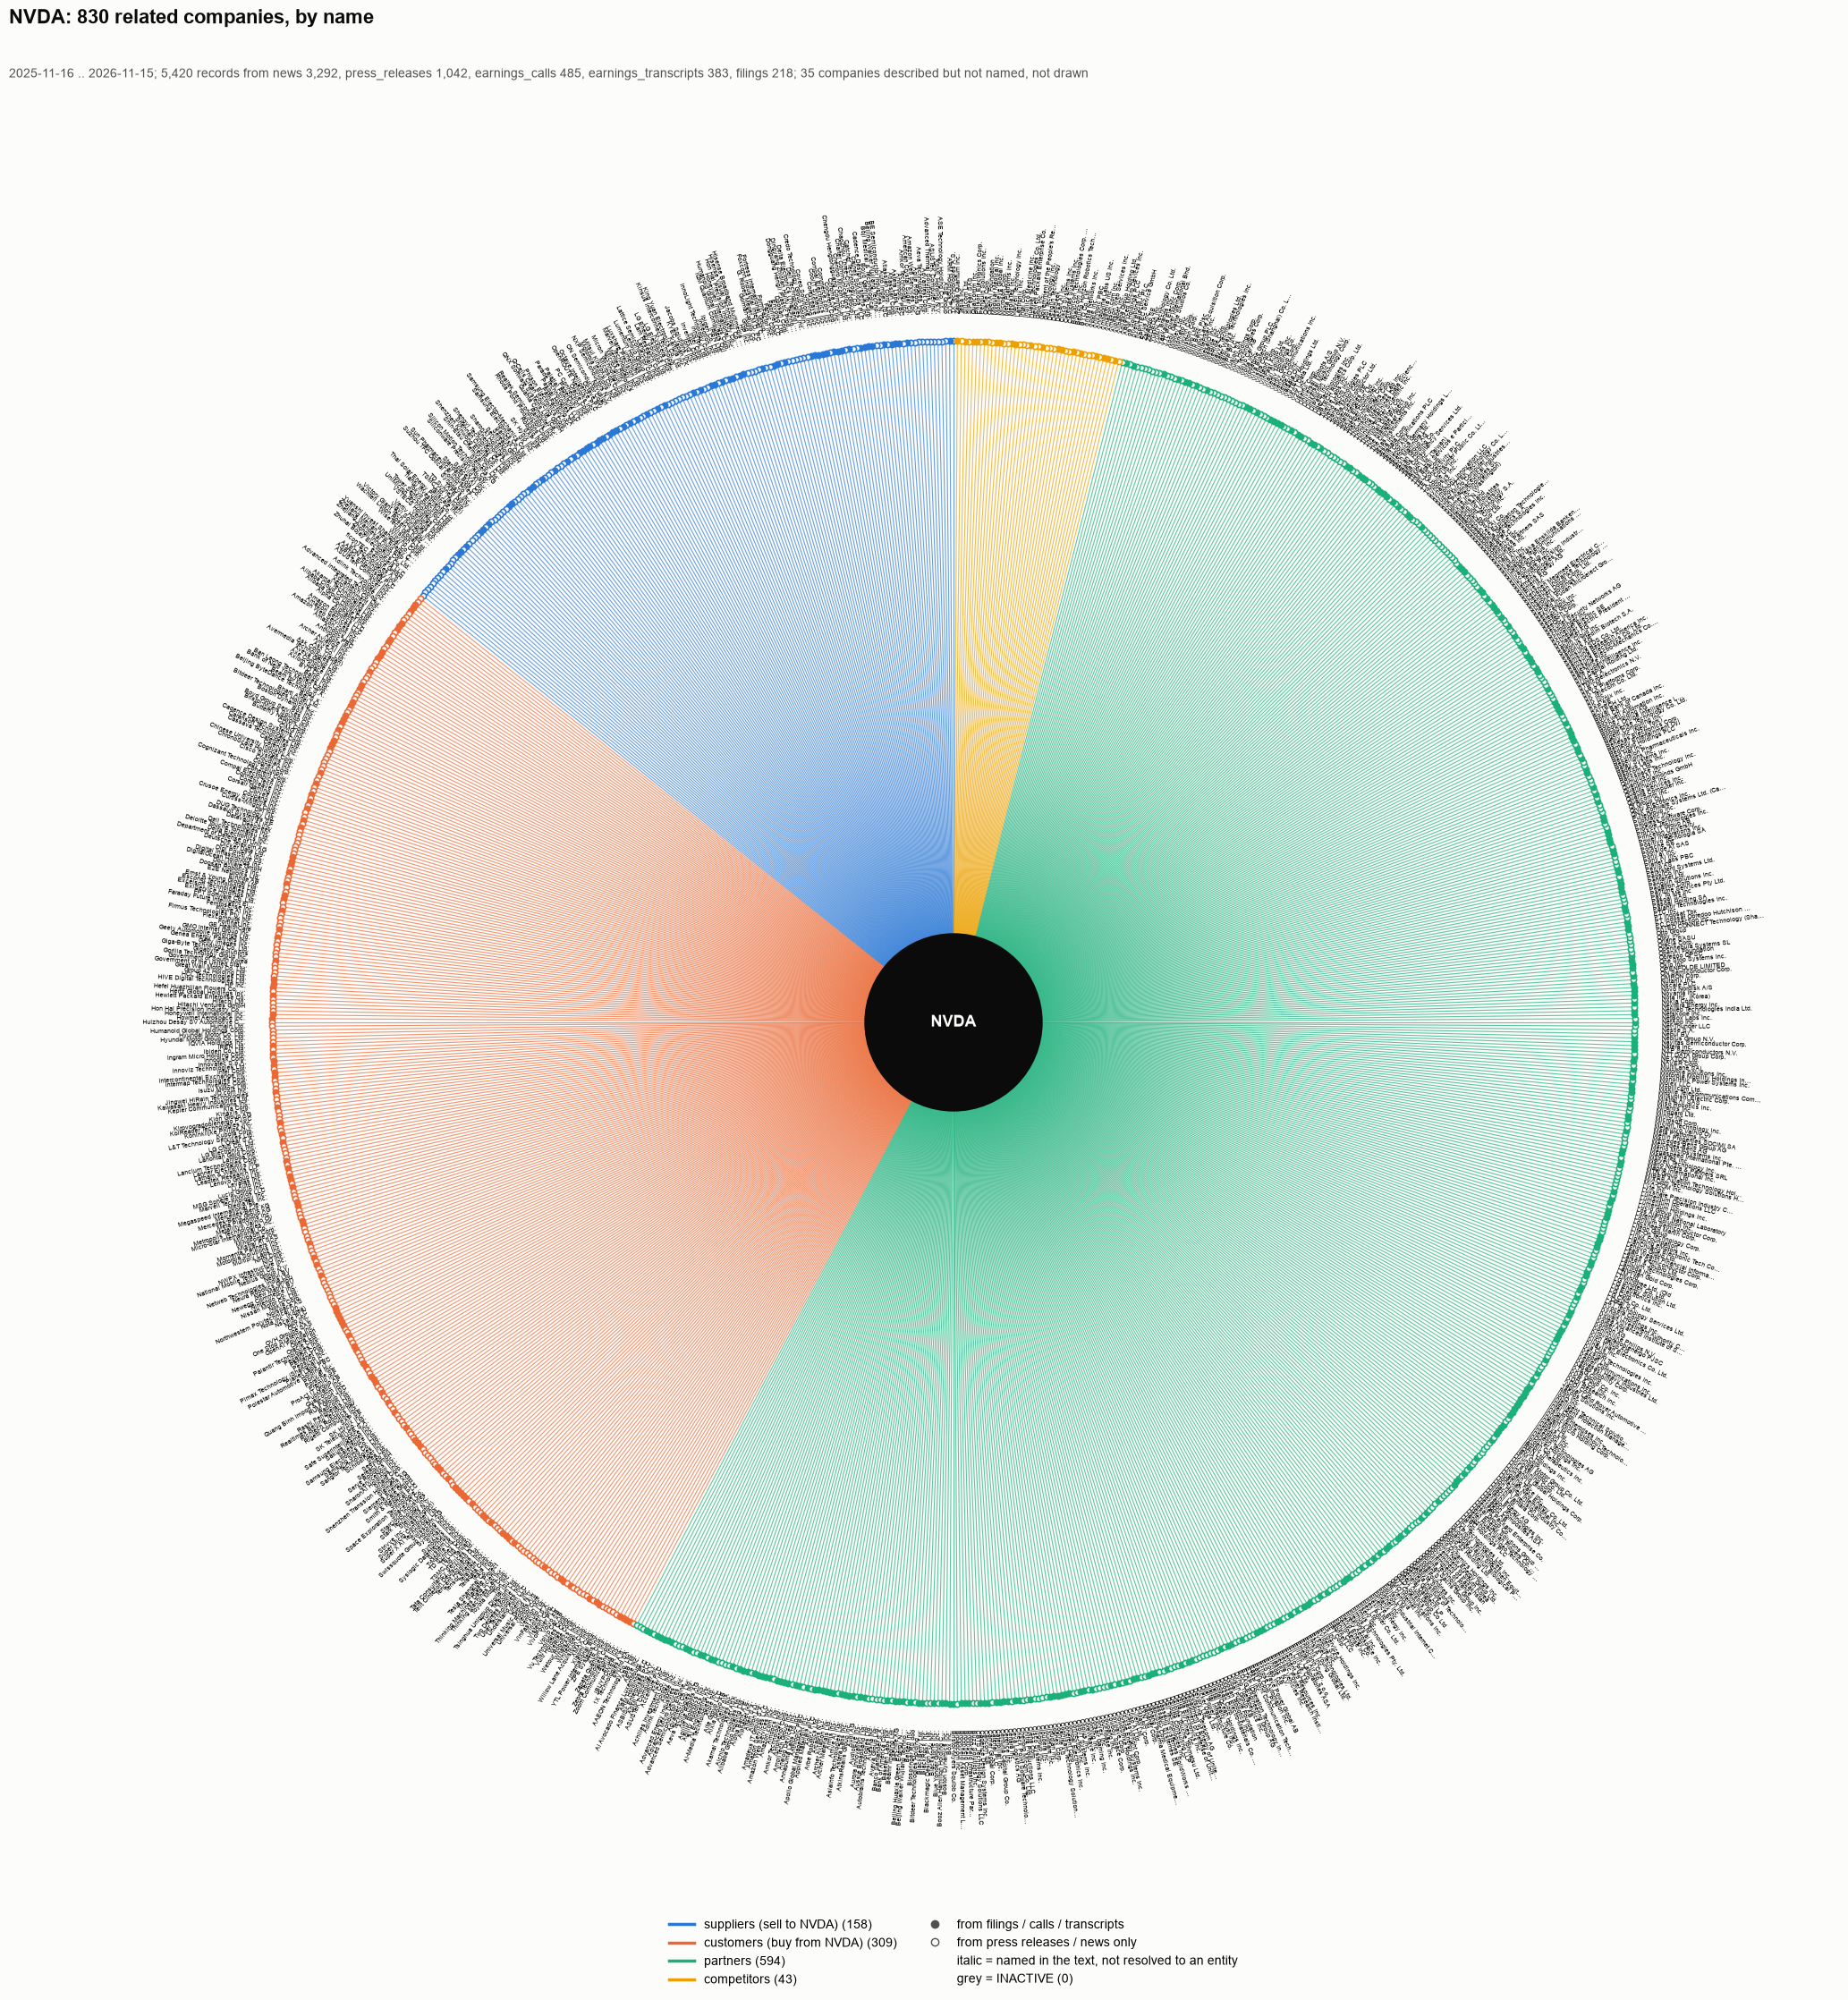

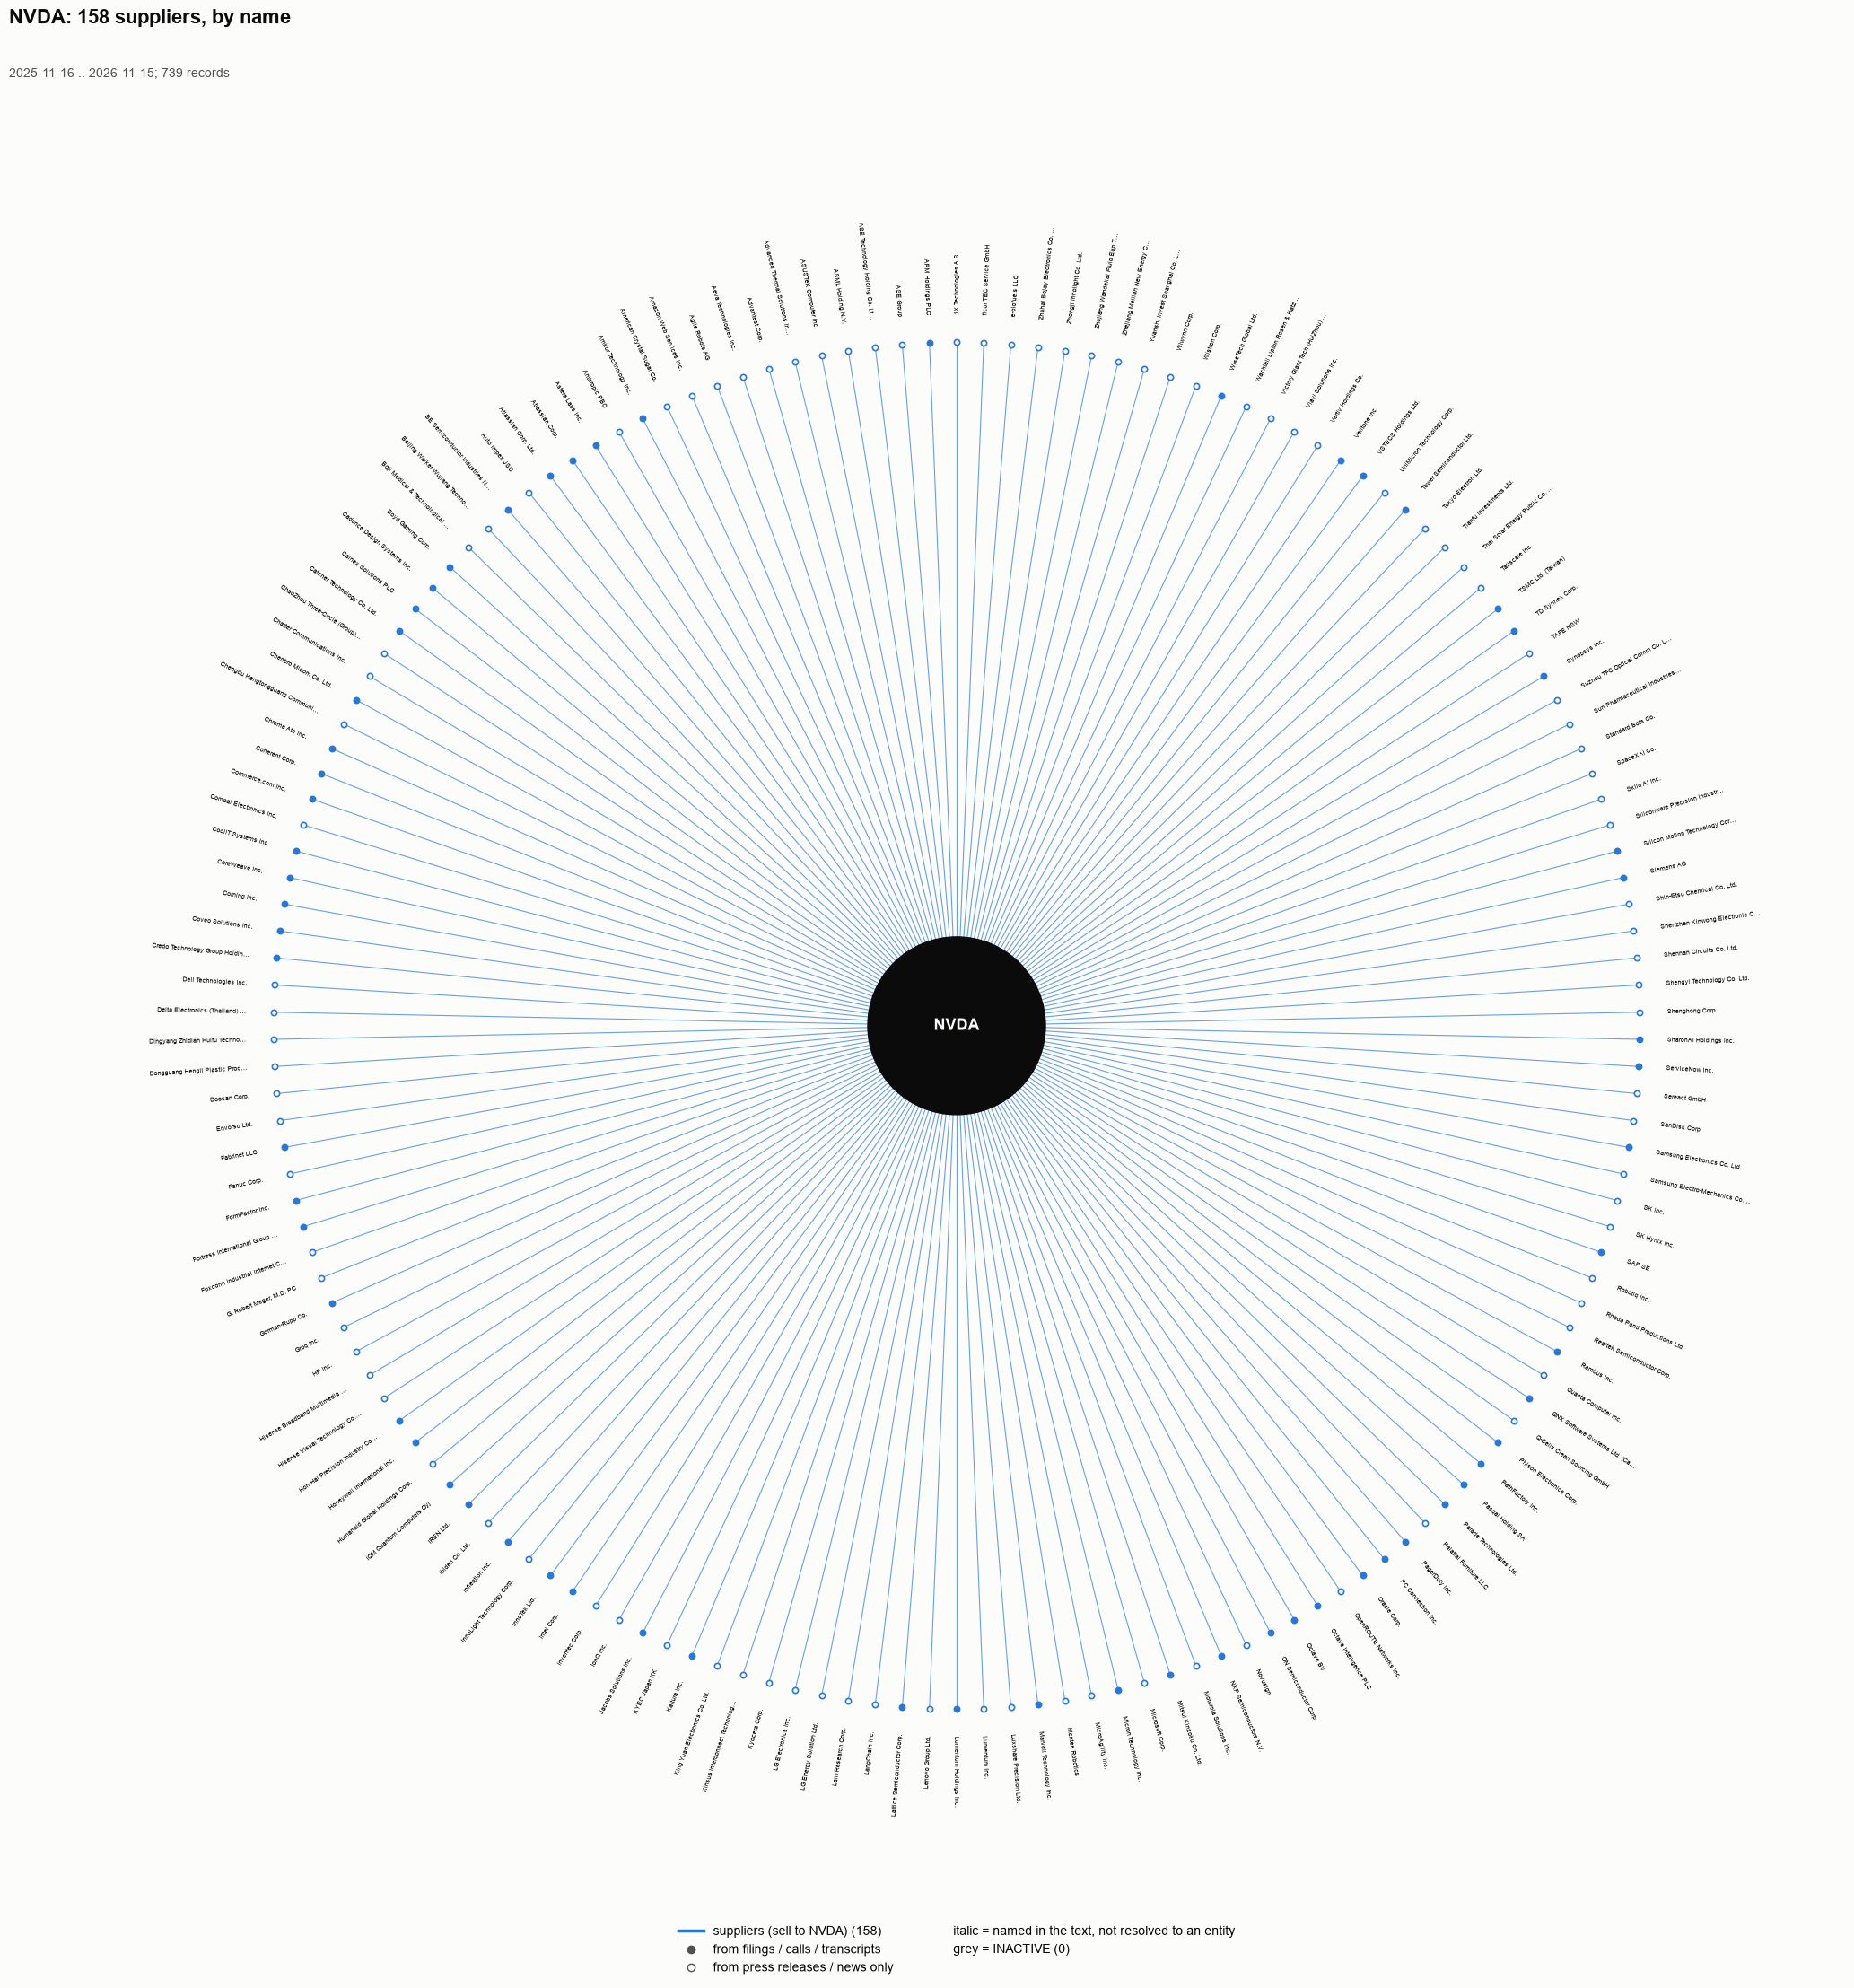

In [26]:
by_source = mine.source_id.value_counts()
subtitle = (
    f"{START} .. {END}; {len(mine):,} records from "
    + ", ".join(f"{k} {v:,}" for k, v in by_source.items())
    + (f"; {int(related.described.sum())} companies described but not named, not drawn" if related.described.any() else "")
)
if len(named_related):
    plot_related(named_related, LABEL, subtitle, OUTPUT_DIR / f"{LABEL}_related_companies.png")
else:
    print(f"{me.name}: no related company found, nothing to draw")
suppliers = named_related[named_related.role == "supplier"]
if len(suppliers):
    plot_related(suppliers, LABEL, f"{START} .. {END}; {int(suppliers.records.sum()):,} records", what="suppliers")

### The grounding of one relationship
Every record behind a relationship: the date, the document, the quoted sentence and its link. Here
the supplier with most records; `evidence("name")` shows any other.

In [27]:
if len(suppliers):
    top = suppliers.iloc[0].counterparty
    print(top)
    display(evidence(top))

TSMC Ltd. (Taiwan)


,document_date,subject_name,relationship_type,object_name,evidence,source_id,headline,record_notes,url,chunk_id
0,2025-11-25,TSMC Ltd. (Taiwan),SUPPLIER_TO,NVIDIA Corp.,Components and parts,news,TSMC sues former top executive who joined US rival Intel,"TSMC, which supplies companies including Nvidia, AMD, Broadcom and Apple, makes more than 90 per cent of the world's most advanced chips and has in recent years widened its lead over rivals Samsun...",https://www.ft.com/content/d05ce62c-2ee2-485a-a0b8-2f7c37473c3e,9020FF553F5ACC0B1C85D75CDFDD0AF3_2
1,2025-12-01,TSMC Ltd. (Taiwan),SUPPLIER_TO,NVIDIA Corp.,Unspecified supply,news,"Samsung Reportedly Hits 55-60% 2nm Yields, Eyeing an Edge Through Early GAA Deployment (Tuesday, November 25, 2025)","With TSMC facing strong demand from customers like NVIDIA and Apple, its 2nm wafers are reportedly priced about 50% higher than previous generations.",https://www.design-reuse.com/news/202529730-samsung-reportedly-hits-55-60-2nm-yields-eyeing-an-edge-through-early-gaa-deployment/,84FA05D668F7DA7393B0A76FB21DA3A5_2
2,2025-12-08,TSMC Ltd. (Taiwan),SUPPLIER_TO,NVIDIA Corp.,Contract manufacturing,news,This Cash-Machine Stock Is Set to Triple Over the Next 5 Years,Both companies outsource their chip production to Taiwan Semiconductor,https://www.nasdaq.com/articles/cash-machine-stock-set-triple-over-next-5-years,5B53EA9D7A2CD90A069F00AC866C9C08_1
3,2025-12-08,TSMC Ltd. (Taiwan),SUPPLIER_TO,NVIDIA Corp.,Contract manufacturing,news,This Cash-Machine Stock Is Set to Triple Over the Next 5 Years,"Both companies outsource their chip production to Taiwan Semiconductor, and the technology these two produce wouldn't be possible without the impressive capabilities TSMC has developed.",https://finance.yahoo.com/news/cash-machine-stock-set-triple-035900541.html,C9BC01E50221628E0C51382AA851B7E8_2
4,2025-12-11,TSMC Ltd. (Taiwan),SUPPLIER_TO,NVIDIA Corp.,Contract manufacturing,news,Wafer Dicing Services Market Set to Exceed US$ 932.9 Million by 2035 | Astute Analytica,TSMC estimates that 60% of its expanded CoWoS capacity in 2025 will be consumed by NVIDIA alone.,https://finance.yahoo.com/news/wafer-dicing-services-market-set-133000319.html,1E83B0B6CC7B0E8A8BE65D1A5EE4AD28_5
...,...,...,...,...,...,...,...,...,...,...
148,2026-11-11,TSMC Ltd. (Taiwan),SUPPLIER_TO,NVIDIA Corp.,Unspecified supply,news,ASE Group's growth is accelerating; the common patron behind its subsidiary SPIL's CoWoS and CPO: NVIDIA! An R&D veteran recounts the details of a 10-year layout in a new track,the shortage of CoWoS capacity led NVIDIA to begin requesting division of labor from TSMC.,https://www.businesstoday.com.tw/article/category/183015/post/202611110004/,DFF3973EDE42EA0C604F758FF6DA509D_4
149,2026-11-12,NVIDIA Corp.,CUSTOMER_OF,TSMC Ltd. (Taiwan),Contract manufacturing,filings,"CoreWeave, Inc. files FORM 10-Q for Q3, FY 2026 on Nov 12, 2026","For example, NVIDIA relies on suppliers such as Taiwan Semiconductor Manufacturing Company for semiconductor fabrication and other manufacturers for compute and networking components.",https://www.sec.gov/Archives/edgar/data/1769628/000176962826000465/crwv-20260930.htm,F267D9CC2CD53A3DF8F910ABC4CAA4C1_170
150,2026-11-12,TSMC Ltd. (Taiwan),PARTNER_WITH,NVIDIA Corp.,Consortium or joint bid,press_releases,UCIe Consortium Advances from Chiplet Connectivity to System-Level Integration with UCIe 4.0 Specification,"UCIe Consortium is led by key industry leaders Advanced Semiconductor Engineering, Inc. (ASE), Alibaba, AMD, Arm, Google Cloud, Intel Corporation, Meta, NVIDIA, Qualcomm Incorporated, Samsung Elec...",http://www.businesswire.com/news/home/20261112413531/en/UCIe-Consortium-Advances-from-Chiplet-Connectivity-to-System-Level-Integration-with-UCIe-4.0-Specification/?feedref=JjAwJuNHiystnCoBq_hl-fqX...,32535615D2FE692C252CE9AA81F10115_6
151,2026-11-15,TSMC Ltd. (Taiwan),SUPPLIER_TO,NVIDIA Corp.,Contract manufacturing,news,Musk warns Nvidia could lose key deals without Huang,"Nvidia's AI 

### Why relations were rejected
What the model read but did not record, and why (the full list in `<LABEL>_rejections.csv`).

In [28]:
if len(graph.rejections):
    display(graph.rejections.rejection_reason.value_counts().rename("relations").to_frame())

,relations
rejection_reason,
ownership_or_ma,1274
co_mention,1174
not_agreed,749
named_not_in_list,502
platform_compatibility,459
named_not_found,366
benchmark_peer,266
id_not_in_chunk,247
speculation,229


### Save the results

In [29]:
outputs = {
    f"{LABEL}_counterparties.csv": related.drop(columns=["key", "active"]),
    f"{LABEL}_relationships.csv": graph.relationships,
    f"{LABEL}_records.csv": graph.records,
    f"{LABEL}_rejections.csv": graph.rejections,
    f"{LABEL}_held_out.csv": graph.held_out,
}
for name, df in outputs.items():
    df.to_csv(OUTPUT_DIR / name, index=False)
    print(f"{OUTPUT_DIR / name}: {len(df):,} rows")

output/NVDA_counterparties.csv: 1,139 rows
output/NVDA_relationships.csv: 4,815 rows


output/NVDA_records.csv: 12,052 rows
output/NVDA_rejections.csv: 6,516 rows
output/NVDA_held_out.csv: 674 rows


## 9. Notes and limitations

- **Only what the text states.** The model records a relationship only when the text says it:
  not co-mentions, rankings, ownership and M&A, lending, litigation, speculation or market
  commentary. A relationship ends only when the text states the end, or after 12 months without
  new evidence.
- **Model noise.** Asking the model again about the same chunks changes about 7% of the pairs,
  almost all of them with a single record. About two pairs in three have a single record: filter on
  `records >= 2` or `first_class` for a more certain list.
- **News is sampled.** 10% of the news chunks are read (`SHARE_NEWS`). The choice is fixed per
  chunk: a larger share reads the same chunks plus new ones, and the cached answers are reused.
- **The news rule trusts the publisher, not the text.** The rank rates a publisher, not an
  article: a rank 1 publisher can carry a rumour and a rank 3 one an official announcement. In
  RavenPack's checks, most relationships the rule leaves out are stated in the text (they are in
  `<LABEL>_held_out.csv`), and since only 10% of the news is read, one with a single rank 3
  publisher may have others in the news not read. `NEWS_RULE = "sources"` with
  `NEWS_MIN_SOURCES = 1` keeps every relationship.
- **Names the model finds.** A company the text names but Bigdata.com did not tag is looked up by
  name and the first company returned is used. About 80% of the names are found; short names and
  acronyms are sometimes resolved to the wrong company.
- **Institutions** (governments, agencies, universities) can be counterparties. A few errors were
  seen: a government read as a competitor, generic names ("Federal Republic").
- **Search limits.** A search returns at most 1,000 chunks per month and basket; the search cell
  reports how many were cut (a few, all in news, for NVIDIA).
- **Time and cost.** The estimate in section 5 uses the rate measured on 2026-11-23 (about 50 calls
  per minute with 8 workers, about 1 USD per 1,000 calls); OpenAI's rate limits and prices decide
  the real figures.